In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import cmocean

import src.plotting as plot
import src.utils as utils
from src.config import *

In [3]:
DIR_AMOC_ON = os.path.join(DIR_OUTPUT, "pi", "pi-amoc-on")
DIR_AMOC_ON_FW = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-on", "fw")
DIR_AMOC_ON_FW_OUTPUT = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-on", "fw_output")    # for yearly output near at equilibrium points
DIR_AMOC_ON_BW = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-on", "bw")
DIR_AMOC_ON_BW_OUTPUT = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-on", "bw_output")    # for yearly output near at equilibrium points

DIR_AMOC_OFF = os.path.join(DIR_OUTPUT, "pi", "pi-amoc-off")
DIR_AMOC_OFF_FW = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-off", "fw")
DIR_AMOC_OFF_FW_OUTPUT = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-off", "fw_output")    # for yearly output near at equilibrium points
DIR_AMOC_OFF_BW = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-off", "bw")
DIR_AMOC_OFF_BW_OUTPUT = os.path.join(DIR_OUTPUT, "hyster-yelmo", "amoc-off", "bw_output")    # for yearly output near at equilibrium points

model_ice = "yelmo"

In [4]:
# ds_GIS_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON_FW, "co2_400_420_run-1", "ice_GRL-16KM_ts.nc"))
# ds_GIS_ts["V_sle"].values[-1]
# np.float32(3.6015475)

In [5]:
# List of runs from amoc-on scenario
runs_amoc_on_fw = os.listdir(DIR_AMOC_ON_FW)
runs_amoc_on_fw.sort()
runs_amoc_on_bw = os.listdir(DIR_AMOC_ON_BW)
runs_amoc_on_bw.sort()
print(runs_amoc_on_fw)
print(runs_amoc_on_bw)

# List of runs from amoc-off scenario
runs_amoc_off_fw = os.listdir(DIR_AMOC_OFF_FW)
runs_amoc_off_fw.sort()
runs_amoc_off_bw = os.listdir(DIR_AMOC_OFF_BW)
runs_amoc_off_bw.sort()
print(runs_amoc_off_fw)
print(runs_amoc_off_bw)

['co2_180_160_run-1', 'co2_200_180_run-1', 'co2_220_200_run-1', 'co2_240_220_run-1', 'co2_260_240_run-1', 'co2_280_260_run-1', 'co2_280_260_run-2', 'co2_280_300_run-1', 'co2_300_320_run-1', 'co2_300_320_run-2', 'co2_300_320_run-3', 'co2_320_340_run-1', 'co2_340_360_run-1', 'co2_360_380_run-1', 'co2_380_400_run-1', 'co2_400_420_run-1', 'co2_400_420_run-2', 'co2_420_440_run-1', 'co2_440_460_run-1']
['co2_160_180_run-1', 'co2_160_180_run-2', 'co2_180_160_run-1', 'co2_180_160_run-2', 'co2_180_160_run-3', 'co2_180_160_run-4', 'co2_180_200_run-1', 'co2_200_180_run-1', 'co2_200_220_run-1', 'co2_220_200_run-1', 'co2_220_200_run-2', 'co2_240_220_run-1', 'co2_260_240_run-1', 'co2_280_260_run-1', 'co2_300_280_run-1', 'co2_300_280_run-2', 'co2_320_300_run-1', 'co2_340_320_run-1', 'co2_360_340_run-1', 'co2_380_360_run-1', 'co2_400_380_run-1', 'co2_420_400_run-1', 'vilma_restart']
['co2_200_180_run-1', 'co2_220_200_run-1', 'co2_240_220_run-1', 'co2_260_240_run-1', 'co2_280_260_run-1', 'co2_280_300_r

In [6]:
# List of final runs from amoc-on scenario. What is meant with this is that some the simulations
# for certain CO2 values have been split over multiple runs (because the ice sheet was not
# in equilibrium at the end of the first run). This list contains the last run for each CO2 value.
runs_amoc_on_fw_final = [
    "co2_180_160_run-1",
    "co2_200_180_run-1",
    "co2_220_200_run-1",
    "co2_240_220_run-1",
    "co2_260_240_run-1",
    "co2_280_260_run-2",
    "co2_280_300_run-1",
    "co2_300_320_run-3",
    "co2_320_340_run-1",
    "co2_340_360_run-1",
    "co2_360_380_run-1",
    "co2_380_400_run-1",
    "co2_400_420_run-2",
    "co2_420_440_run-1",
    "co2_440_460_run-1",
]

runs_amoc_on_fw_output = [
    "co2_160",
    "co2_180",
    "co2_200",
    "co2_220",
    "co2_240",
    "co2_260",
    "co2_300",
    "co2_320",
    "co2_340",
    "co2_360",
    "co2_380",
    "co2_400",
    "co2_420",
    "co2_440",
    "co2_460",
]

runs_amoc_on_bw_final = [
    "co2_420_400_run-1",
    "co2_400_380_run-1",
    "co2_380_360_run-1",
    "co2_360_340_run-1",
    "co2_340_320_run-1",
    "co2_320_300_run-1",
    "co2_300_280_run-2",
    "co2_280_260_run-1",
    "co2_260_240_run-1",
    "co2_240_220_run-1",
    "co2_220_200_run-2",
    "co2_200_180_run-1",
    "co2_180_160_run-4",
]

runs_amoc_on_bw_output = [
    "co2_400",
    "co2_380",
    "co2_360",
    "co2_340",
    "co2_320",
    "co2_300",
    "co2_280",
    "co2_260",
    "co2_240",
    "co2_220",
    "co2_200",
    "co2_180",
    "co2_160",
]

# List of final runs from amoc-off scenario. What is meant with this is that some the simulations
# for certain CO2 values have been split over multiple runs (because the ice sheet was not
# in equilibrium at the end of the first run). This list contains the last run for each CO2 value.
runs_amoc_off_fw_final = [
    "co2_200_180_run-1",
    "co2_220_200_run-1",
    "co2_240_220_run-1",
    "co2_260_240_run-1",
    "co2_280_260_run-1",
    "co2_280_300_run-1",
    "co2_300_320_run-1",
    "co2_320_340_run-1",
    "co2_340_360_run-1",
    "co2_360_380_run-1",
    "co2_380_400_run-1",
    "co2_400_420_run-1",
    "co2_420_440_run-1",
    "co2_440_460_run-1",
    "co2_460_480_run-1",
    "co2_480_500_run-1",
    "co2_500_520_run-2",
    "co2_520_540_run-2",
    "co2_540_560_run-3",
    "co2_560_580_run-2",
    "co2_580_600_run-1",
    # "co2_560_580_run-2_redo_test_old",    # branched off at year_30000 from "co2_560_580_run-1_redo_test"
    # "co2_580_600_run-1_old",    # branched off at year_50000 from "co2_560_580_run-2_redo_test"
]

runs_amoc_off_fw_output = [
    "co2_180",
    "co2_200",
    "co2_220",
    "co2_240",
    "co2_260",
    "co2_300",
    "co2_320",
    "co2_340",
    "co2_360",
    "co2_380",
    "co2_400",
    "co2_420",
    "co2_440",
    "co2_460",
    "co2_480",
    "co2_500",
    "co2_520",
    "co2_540",
    "co2_560",
    "co2_580",
    "co2_600",
]

runs_amoc_off_bw_final = [
    "co2_580_560_run-1",    
    "co2_560_540_run-1",
    "co2_540_520_run-1",
    "co2_520_500_run-1",
    "co2_500_480_run-1",
    "co2_480_460_run-1",
    "co2_460_440_run-1",
    "co2_440_420_run-1",
    "co2_420_400_run-1",
    "co2_400_380_run-1",
    "co2_380_360_run-1",
    "co2_360_340_run-1",
    "co2_340_320_run-2",
    "co2_320_300_run-1",
    "co2_300_280_run-1",
    "co2_280_260_run-2",
    "co2_260_240_run-1",
    "co2_240_220_run-1",
    "co2_220_200_run-1",
    "co2_200_180_run-5",
]

runs_amoc_off_bw_output = [
    "co2_560",
    "co2_540",
    "co2_520",
    "co2_500",
    "co2_480",
    "co2_460",
    "co2_440",
    "co2_420",
    "co2_400",
    "co2_380",
    "co2_360",
    "co2_340",
    "co2_320",
    "co2_300",
    "co2_280",
    "co2_260",
    "co2_240",
    "co2_220",
    "co2_200",
    "co2_180",
]

# CO2 concentrations for both scenarios
CO2_amoc_on_fw = [160, 180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460]
CO2_amoc_on_fw_output = [160, 180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460]
CO2_amoc_on_bw = [420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180, 160,]
CO2_amoc_on_bw_output = [420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180, 160]

CO2_amoc_off_fw = [180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460, 480, 500, 520, 540, 560, 580, 600]
CO2_amoc_off_fw_output = [180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460, 480, 500, 520, 540, 560, 580, 600]
CO2_amoc_off_bw = [580, 560, 540, 520, 500, 480, 460, 440, 420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180,]
CO2_amoc_off_bw_output = [580, 560, 540, 520, 500, 480, 460, 440, 420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180]

# Offset what index to insert PI state in the fw branches (because it is computed from preindustrial control)
insert_offset_amoc_on = 6
insert_offset_amoc_off = 5

In [7]:
def load_final_states_hyster_ts(DIR, runs, var="V_sle", dataset="ice_GRL-16KM_ts.nc", n_years=1000):
    """
    Load the final states of the quasi-equilibrium runs.

    Parameters
    ----------
    DIR : str
        The directory containing the hysteresis runs.
    runs : list
        The list of runs to load.

    Returns
    -------
    final_states : list
        The final states of the runs.
    """
    final_states = []

    # Check if runs is list or 1d array, if not make it a list
    # If runs is None, DIR contains full path, set runs to empty string to avoid error in os.path.join
    if runs is None:
        runs = [""]
    elif not isinstance(runs, (list, np.ndarray)):
        runs = [runs]

    for run in runs:
        fpath = os.path.join(DIR, run, dataset)
        ds = xr.open_dataset(fpath, mode='r')

        # Get the final state of the run
        final_states.append(float(np.mean(ds[var].values[-n_years:])))

    return final_states


def load_final_states_hyster_mb(DIR, runs, var="mb_net", dataset="ice_GRL-16KM.nc", n_years=100):
    """
    Load the final states of the quasi-equilibrium runs.

    Parameters
    ----------
    DIR : str
        The directory containing the hysteresis runs.
    runs : list
        The list of runs to load.

    Returns
    -------
    final_states : list
        The final states of the runs.
    """
    final_states = []

    # Check if runs is list or 1d array, if not make it a list
    # If runs is None, DIR contains full path, set runs to empty string to avoid error in os.path.join
    if runs is None:
        runs = [""]
    elif not isinstance(runs, (list, np.ndarray)):
        runs = [runs]

    for run in runs:
        fpath = os.path.join(DIR, run, dataset)
        ds = xr.open_dataset(fpath, mode='r')

        # Get the final state of the run
        mb_net = np.mean(ds[var].isel(time=slice(-n_years, None)).sum(dim=["xc", "yc"]).values)
        final_states.append(float(mb_net))

    return final_states


def load_final_states_hyster_atm(DIR, runs, mask, var="tg", dataset="atm.nc", cumulative=False, months=12, n_years=1000):
    """
    Load the final states of the quasi-equilibrium runs for the atmospheric variable.
    This is from the full 3D field.

    Parameters
    ----------
    DIR : str
        The directory containing the hysteresis runs.
    runs : list
        The list of runs to load.
    months : list
        The list of months to average over (0-based indexing, e.g. [0, 1, 2] for Jan-Mar). 12 is yearly
    cumulative : bool
        Whether to sum over the months instead of averaging (for integrated quantities like precipitation).
    Returns
    -------
    final_states : list
        The final states of the runs.
    """
    final_states = []

    # Check if runs is list or 1d array, if not make it a list
    # If runs is None, DIR contains full path, set runs to empty string to avoid error in os.path.join
    if runs is None:
        runs = [""]
    elif not isinstance(runs, (list, np.ndarray)):
        runs = [runs]
        
    # print(f"Loading final states for runs: {runs}")

    for run in runs:
        fpath = os.path.join(DIR, run, dataset)
        ds = xr.open_dataset(fpath, mode='r')

        # Get the final state of the run
        # Pre-select smaller area to save costs.
        try:
            da = ds[var].sel(lat=slice(55, 86), lon=slice(-75, -5))
        except KeyError:
            print(f"Not enough timepoints for variable in {run}. Skipping...")
            final_states.append(np.nan)
            continue

        # Mask to include data only above Greenland
        da_masked = da.where(mask)

        # Calculate spatial weighted average
        weights = xr.DataArray(
            np.cos(np.deg2rad(da_masked.lat)),
            coords={"lat": da_masked.lat},
            dims=["lat"],
        )

        avg = (
            da_masked
            .isel(mon=months, time=slice(-n_years, None))
            .weighted(weights)
            .mean(dim=["lat", "lon"])
        )

        # Check if time is dimension in avg
        if "mon" in avg.dims:

            # If we want integrated quantity, sum over the months instead of averaging
            if cumulative:
                avg = avg.sum("mon")
            else:
                avg = avg.mean("mon")

        if "time" in avg.dims:
            avg = avg.mean("time")
        # print(avg)
        final_states.append(float(avg.values))
    
    return final_states


def load_and_plot_ice_thickness(DIR, time_ind, ax, proj=None, title=None):
    """
    Load the ice thickness dataset and delegate plotting to plot.plot_GIS_contourf_yelmo.

    Parameters
    ----------
    DIR : str
        Directory containing the experiment output.
    time_ind : int
        Time index to plot.
    ax : matplotlib.axes.Axes
        Axis to plot on.
    proj : cartopy.crs projection
        Kept for backward compatibility with existing calls.
    title : str
        Title for the subplot.

    Returns
    -------
    cf : matplotlib.contour.QuadContourSet
        Contourf object for shared colorbar creation.
    """

    fpath_GIS = os.path.join(DIR, "ice_GRL-16KM.nc")
    ds_GIS = xr.open_dataset(fpath_GIS, mode="r")

    mask = ds_GIS["mask_bed"].isel(time=time_ind) > 0

    fig, ax, cf = plot.plot_GIS_contourf_yelmo(
        ds_GIS,
        "H_ice",
        time_index=time_ind,
        mask=mask,
        ax=ax,
        levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5],
        title=title,
    )

    return cf

In [8]:
# Load preindustrial control data
ds_atm_pi_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, "atm_ts.nc"), mode='r')
ds_atm_pi_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "atm_ts.nc"), mode='r')

ds_atm_pi_amoc_on = xr.open_dataset(os.path.join(DIR_AMOC_ON, "atm.nc"), mode='r')
ds_atm_pi_amoc_off = xr.open_dataset(os.path.join(DIR_AMOC_OFF, "atm.nc"), mode='r')

ds_GIS_pi_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, 'ice_GRL-16KM_ts.nc'), mode='r')
ds_GIS_pi_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, 'ice_GRL-16KM_ts.nc'), mode='r')

ds_smb_pi_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, 'smb_GRL-16KM_ts.nc'), mode='r')
ds_smb_pi_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, 'smb_GRL-16KM_ts.nc'), mode='r')

ds_bmb_pi_amoc_on_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON, 'bmb_GRL-16KM_ts.nc'), mode='r')
ds_bmb_pi_amoc_off_ts = xr.open_dataset(os.path.join(DIR_AMOC_OFF, 'bmb_GRL-16KM_ts.nc'), mode='r')


# Create atmosphere mask for Greenland
mask_grl_atm = utils.create_grl_atm_mask(ds_atm_pi_amoc_on.lon, ds_atm_pi_amoc_on.lat)

In [9]:
ds_atm_pi_amoc_on

<xarray.Dataset> Size: 48GB
Dimensions:          (time: 1000, mon: 13, lat: 36, lon: 72, doy: 360,
                      hour: 24, zlay: 13, zlev: 13, zlevw: 14, plev: 13,
                      plevw: 14, lonu: 73, latv: 37, st: 5)
Coordinates: (12/14)
  * time             (time) float64 8kB 1.0 2.0 3.0 4.0 ... 998.0 999.0 1e+03
  * mon              (mon) float64 104B 1.0 2.0 3.0 4.0 ... 10.0 11.0 12.0 13.0
  * lat              (lat) float64 288B -87.5 -82.5 -77.5 ... 77.5 82.5 87.5
  * lon              (lon) float64 576B -177.5 -172.5 -167.5 ... 172.5 177.5
  * doy              (doy) float64 3kB 1.0 2.0 3.0 4.0 ... 358.0 359.0 360.0
  * hour             (hour) float64 192B 1.0 2.0 3.0 4.0 ... 21.0 22.0 23.0 24.0
    ...               ...
  * zlevw            (zlevw) float64 112B -0.0 202.4 410.0 ... 1.84e+04 3e+04
  * plev             (plev) float64 104B 1e+03 975.0 950.0 ... 300.0 200.0 100.0
  * plevw            (plevw) float64 112B 1e+03 975.0 950.0 ... 200.0 100.0 0.0
  * lonu             (lonu) float64 584B -180.0 -175.0 -170.0 ... 175.0 180.0
  * latv             (latv) float64 296B -90.0 -85.0 -80.0 ... 80.0 85.0 90.0
  * st               (st) float64 40B 1.0 2.0 3.0 4.0 5.0
Data variables: (12/189)
    had_fi           (time, mon) float32 52kB ...
    had_width        (time, mon) float32 52kB ...
    ptrop            (time, mon, lat) float32 2MB ...
    tslz             (time, mon, lat) float32 2MB ...
    tskslz           (time, mon, lat) float32 2MB ...
    ekez             (time, mon, lat) float32 2MB ...
    ...               ...
    slope_y          (time, lat, lon) float32 10MB ...
    frlnd            (time, lat, lon) float32 10MB ...
    frocn            (time, lat, lon) float32 10MB ...
    zs               (time, st, lat, lon) float32 52MB ...
    fw_pac_atl       (time, lat) float32 144kB ...
    fw_atl_indpac    (time, lat) float32 144kB ...

In [10]:
### Calculate preindustrial temperature and difference over 1000 years
tg_pi_amoc_on = ds_atm_pi_amoc_on_ts["tg"][-1000:].mean()
tg_pi_amoc_off = ds_atm_pi_amoc_off_ts["tg"][-1000:].mean()

# Difference in preindustrial temperature between the two scenarios
tg_pi_diff = tg_pi_amoc_off - tg_pi_amoc_on
print(f"Difference in preindustrial temperature between AMOC off and AMOC on: {tg_pi_diff.values:.2f} K")

Difference in preindustrial temperature between AMOC off and AMOC on: -0.26 K


In [11]:
# Global warming levels at different CO2
tg_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW, runs_amoc_on_fw_final, var="tg", dataset="atm_ts.nc", n_years=1000)
delta_tg_amoc_on_fw = [tg - float(tg_pi_amoc_on) for tg in tg_amoc_on_fw]
delta_tg_amoc_on_fw.insert(insert_offset_amoc_on, 0)

tg_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW, runs_amoc_on_bw_final, var="tg", dataset="atm_ts.nc", n_years=1000)
delta_tg_amoc_on_bw = [tg - float(tg_pi_amoc_on) for tg in tg_amoc_on_bw]
delta_tg_amoc_on_bw.insert(0, delta_tg_amoc_on_fw[-3])   # start backward branch from the state of the forward branch at 420 ppm

tg_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, runs_amoc_off_fw_final, var="tg", dataset="atm_ts.nc", n_years=1000)
delta_tg_amoc_off_fw = [tg - float(tg_pi_amoc_on) for tg in tg_amoc_off_fw]
delta_tg_amoc_off_fw.insert(insert_offset_amoc_off, float(tg_pi_diff))

tg_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW, runs_amoc_off_bw_final, var="tg", dataset="atm_ts.nc", n_years=1000)
delta_tg_amoc_off_bw = [tg - float(tg_pi_amoc_on) for tg in tg_amoc_off_bw]
delta_tg_amoc_off_bw.insert(0, delta_tg_amoc_off_fw[-2])   # start backward branch from the state of the forward branch at 580 ppm

print("Global warming levels at CO2 levels")
print(CO2_amoc_on_fw)
print(f"AMOC on forward: {delta_tg_amoc_on_fw}")
print(CO2_amoc_on_bw)
print(f"AMOC on backward: {delta_tg_amoc_on_bw}")
print(CO2_amoc_off_fw)
print(f"AMOC off forward: {delta_tg_amoc_off_fw}")
print(CO2_amoc_off_bw)
print(f"AMOC off backward: {delta_tg_amoc_off_bw}")

Global warming levels at CO2 levels
[160, 180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460]
AMOC on forward: [-2.946843320007991, -2.3132114288018286, -1.7464291061370343, -1.2145588971473789, -0.6858265724460466, -0.3185751487478772, 0, 0.3259428501454362, 0.6563811776459652, 0.9896333720063737, 1.2663737503420673, 1.5523164347925587, 1.7846694992837673, 2.128072444070492, 2.307909710669966, 2.4821682541398484]
[420, 400, 380, 360, 340, 320, 300, 280, 260, 240, 220, 200, 180, 160]
AMOC on backward: [2.128072444070492, 1.9334440724745665, 1.70502940776149, 1.4252183382964319, 1.142414683390097, 0.827355758512736, 0.4789965387206685, 0.13086497022165844, -0.19885767423634348, -0.5470371310362978, -1.0189337751150624, -1.5936112543882217, -2.1378506704953306, -2.970957882051989]
[180, 200, 220, 240, 260, 280, 300, 320, 340, 360, 380, 400, 420, 440, 460, 480, 500, 520, 540, 560, 580, 600]
AMOC off forward: [-2.4342007420959177, -1.9492952879352945, -1.389942949256

In [12]:
# Get the initial GIS state from the end of the pi-amoc-on run
eq_amoc_on_fw_init = float(ds_GIS_pi_amoc_on_ts["V_sle"].values[-1])
eq_amoc_off_fw_init = float(ds_GIS_pi_amoc_off_ts["V_sle"].values[-1])

print(f"Difference in mSLE initial states: {eq_amoc_on_fw_init - eq_amoc_off_fw_init:.4f} mSLE")

# Load the equilibrium GrIS states from the forward and backwards branches for the amoc-on and amoc-off scenarios
# We always use the negative difference with the PI amoc-on GrIS configuration for the V_sle
eq_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW, runs_amoc_on_fw_final, var="V_sle")
eq_amoc_on_fw.insert(insert_offset_amoc_on, eq_amoc_on_fw_init)
eq_amoc_on_fw_diff = np.asarray(eq_amoc_on_fw) - eq_amoc_on_fw_init
print(eq_amoc_on_fw)

eq_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW, runs_amoc_on_bw_final, var="V_sle")
if len(eq_amoc_on_bw) > 0:
    eq_amoc_on_bw.insert(0, eq_amoc_on_fw[-3])   # start backward branch from the state of the forward branch at 420 ppm
eq_amoc_on_bw_diff = np.asarray(eq_amoc_on_bw) - eq_amoc_on_fw_init
print(eq_amoc_on_bw)

eq_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, runs_amoc_off_fw_final, var="V_sle")
eq_amoc_off_fw.insert(insert_offset_amoc_off, eq_amoc_off_fw_init)
eq_amoc_off_fw_diff = np.asarray(eq_amoc_off_fw) - eq_amoc_on_fw_init
print(eq_amoc_off_fw)

eq_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW, runs_amoc_off_bw_final, var="V_sle")
if len(eq_amoc_off_bw) > 0:
    eq_amoc_off_bw.insert(0, eq_amoc_off_fw[-2])   # start backward branch from the state of the forward branch at 580 ppm
eq_amoc_off_bw_diff = np.asarray(eq_amoc_off_bw) - eq_amoc_on_fw_init
print(eq_amoc_off_bw)

Difference in mSLE initial states: 0.8078 mSLE
[7.1650896072387695, 7.129393100738525, 7.084643363952637, 7.136512279510498, 7.318341255187988, 7.424039840698242, 7.536111831665039, 7.5327959060668945, 7.412076950073242, 7.436934471130371, 7.270437717437744, 7.142002582550049, 6.958390712738037, 0.45317742228507996, 0.4545314311981201, 0.43600597977638245]
[0.45317742228507996, 0.4668450653553009, 0.4808489680290222, 0.5097411870956421, 0.5241461396217346, 0.5605814456939697, 0.5807744860649109, 0.7791549563407898, 0.8403655886650085, 0.9110797643661499, 0.8998316526412964, 1.5536463260650635, 1.5743839740753174, 7.383519172668457]
[7.473003387451172, 7.151240348815918, 7.017075061798096, 6.975610256195068, 6.724902153015137, 6.728296756744385, 6.798091411590576, 6.800176620483398, 6.795897960662842, 6.799517631530762, 6.790453910827637, 6.760832786560059, 6.740486145019531, 6.727149486541748, 6.720886707305908, 6.7240777015686035, 6.708248138427734, 6.187337398529053, 6.14854383468627

In [13]:
# Calculate ice sheet loss during the intermediate tipping points in the AMOC-off scenario
print(eq_amoc_off_fw[-6] - eq_amoc_off_fw[-5])
print(eq_amoc_off_fw[-4] - eq_amoc_off_fw[-3])

# Calculate ice sheet difference between PI conditions
print(eq_amoc_on_fw_init, eq_amoc_off_fw_init, eq_amoc_on_fw_init - eq_amoc_off_fw_init)

# Ice sheet loss AMOC-on scenario before tipping
print(eq_amoc_on_fw[0+insert_offset_amoc_on] - eq_amoc_on_fw[6+insert_offset_amoc_on])
print(((eq_amoc_on_fw[0+insert_offset_amoc_on] - eq_amoc_on_fw[6+insert_offset_amoc_on]) / (CO2_amoc_on_fw[0+insert_offset_amoc_on] - CO2_amoc_on_fw[6+insert_offset_amoc_on])) * 100)

0.5209107398986816
1.243974208831787
7.536111831665039 6.728296756744385 0.8078150749206543
0.577721118927002
-0.4814342657725016


### Create the stability diagrams

0.05 0.61


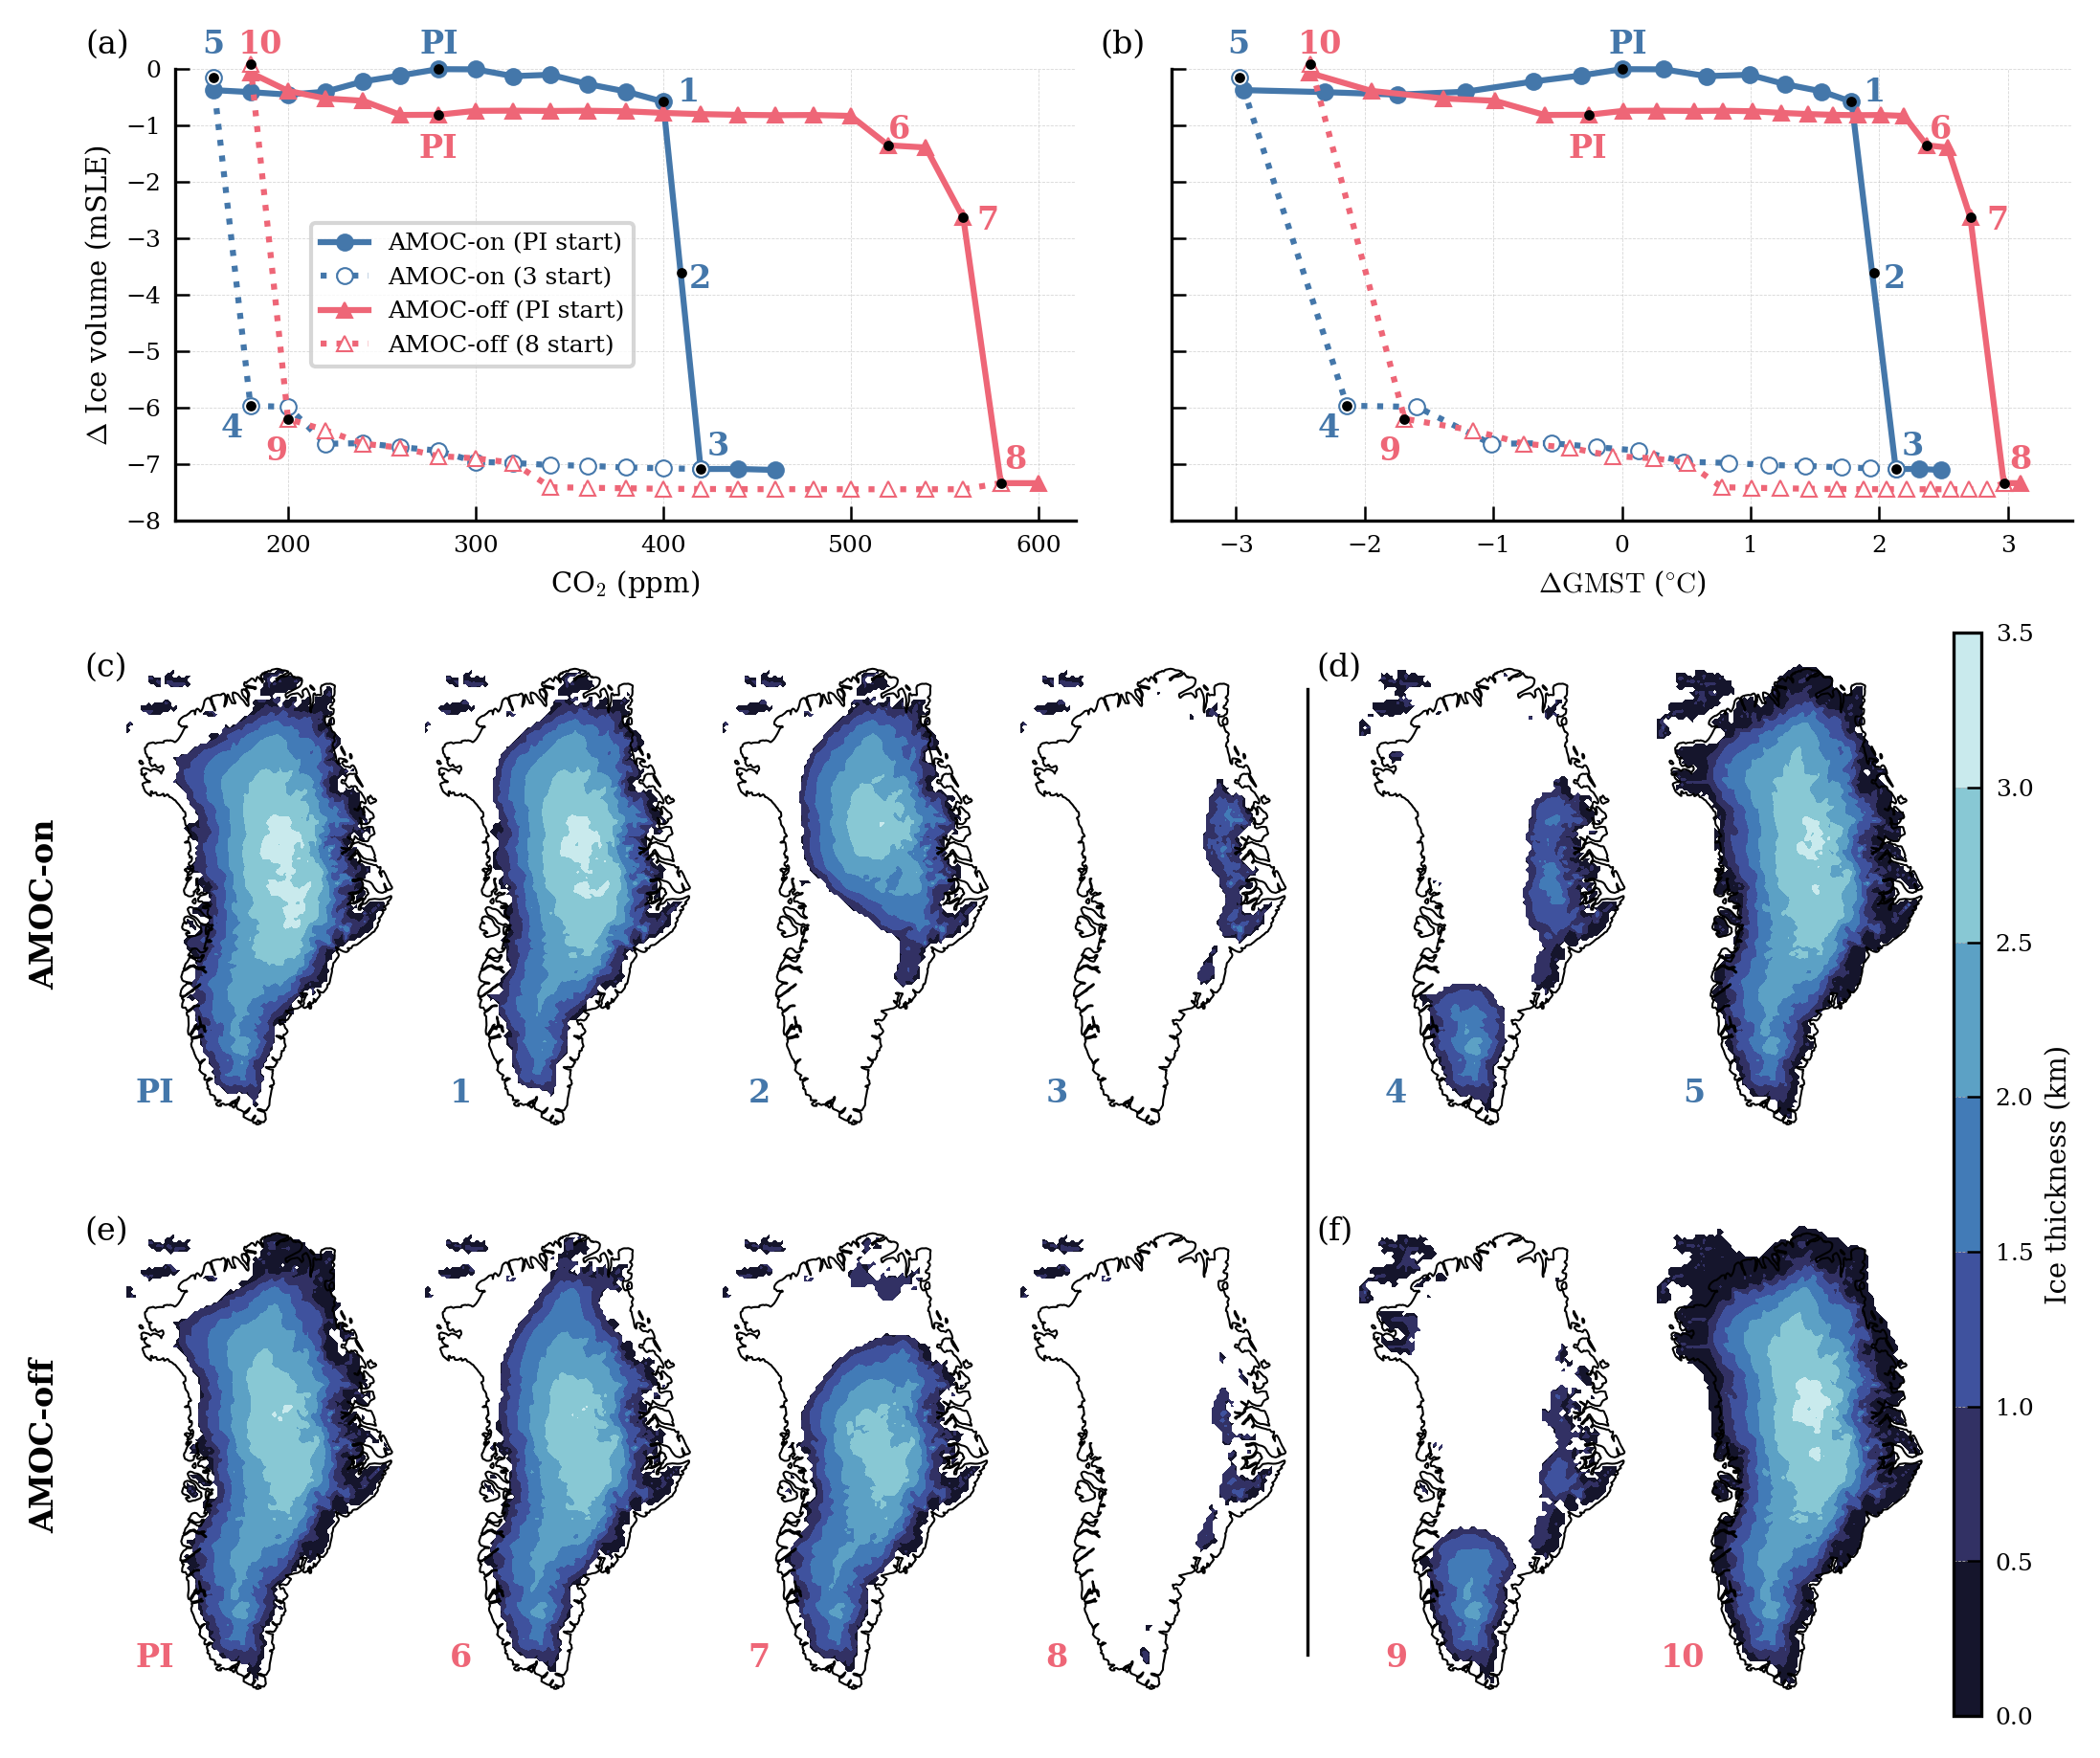

In [14]:
from matplotlib.lines import Line2D


markersize = 4
s_text = 2.5

fig = plt.figure(figsize=(plot.width_twocol, 1.35*plot.height_twocol), constrained_layout=True)
proj = ccrs.Stereographic(central_longitude=-45, central_latitude=90, true_scale_latitude=70)

# Outer grid: 2 rows (top, bottom) + 1 narrow cbar column on the right, 1 narrow col on the left
outer = gridspec.GridSpec(
    2, 3,
    width_ratios=[0.005, 1, 0.015],    # left area + colorbar
    height_ratios=[1.1, 2],
    figure=fig
)

# TOP row: 2 columns inside left area
gs_top = gridspec.GridSpecFromSubplotSpec(
    1, 2,
    subplot_spec=outer[0, 1:3],
)

# BOTTOM row: 4 columns inside left area
gs_bottom = gridspec.GridSpecFromSubplotSpec(
    2, 6,
    subplot_spec=outer[1, 1],
)

# Colorbar area
ax_cb = fig.add_subplot(outer[1, 2])   # only second row

# AMOC state area
ax_amoc_state = fig.add_subplot(outer[1, 0])   # only second row

# ---- Top row (normal axes) ----
ax1 = fig.add_subplot(gs_top[0, 0])
ax2 = fig.add_subplot(gs_top[0, 1])

# ---- Bottom row (projection axes) ----
ax3 = fig.add_subplot(gs_bottom[0, 0], projection=proj)
ax4 = fig.add_subplot(gs_bottom[0, 1], projection=proj)
ax5 = fig.add_subplot(gs_bottom[0, 2], projection=proj)
ax6 = fig.add_subplot(gs_bottom[0, 3], projection=proj)
ax7 = fig.add_subplot(gs_bottom[0, 4], projection=proj)
ax8 = fig.add_subplot(gs_bottom[0, 5], projection=proj)

ax9 = fig.add_subplot(gs_bottom[1, 0], projection=proj)
ax10 = fig.add_subplot(gs_bottom[1, 1], projection=proj)
ax11 = fig.add_subplot(gs_bottom[1, 2], projection=proj)
ax12 = fig.add_subplot(gs_bottom[1, 3], projection=proj)
ax13 = fig.add_subplot(gs_bottom[1, 4], projection=proj)
ax14 = fig.add_subplot(gs_bottom[1, 5], projection=proj)

### Plot mSLE difference with preindustrial w.r.t. CO2
ax1.plot(CO2_amoc_on_fw, eq_amoc_on_fw_diff, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on (PI start)", clip_on=False)
ax1.plot(CO2_amoc_on_bw, eq_amoc_on_bw_diff, marker='o', markerfacecolor="white", markersize=markersize, linestyle=':', color=plot.get_color(0), clip_on=False, label="AMOC-on (3 start)")

ax1.plot(CO2_amoc_off_fw, eq_amoc_off_fw_diff, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off (PI start)", clip_on=False)
ax1.plot(CO2_amoc_off_bw, eq_amoc_off_bw_diff, marker='^', markerfacecolor="white", markersize=markersize, linestyle=':', color=plot.get_color(1), clip_on=False, label="AMOC-off (8 start)")

ax1.set_xlabel("CO$_2$ (ppm)")
ax1.set_ylabel(r"$\Delta$ Ice volume (mSLE)")
ax1.set_xlim(140, 620)
ax1.set_ylim(-8, 0)
ax1.grid(alpha=0.5)

# Add letters from the ice thickness subplots to indicate which CO2 level they correspond to
ax1.text(0.271, 1.02, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.558, 0.915, "1", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.57, 0.5, "2", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.59, 0.13, "3", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.05, 0.17, "4", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.03, 1.02, "5", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')

# Add small black dot on top of the existing scatter to indicate where numbers belong to
ax1.scatter(CO2_amoc_on_fw[0+insert_offset_amoc_on], eq_amoc_on_fw_diff[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_on_fw[6+insert_offset_amoc_on], eq_amoc_on_fw_diff[6+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
# ds_GIS_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON_FW, "co2_400_420_run-1", "ice_GRL-16KM_ts.nc"))
# ds_GIS_ts["V_sle"].values[-1]
# np.float32(3.6015475)
ax1.scatter(np.mean(CO2_amoc_on_fw[6+insert_offset_amoc_on:8+insert_offset_amoc_on]), -3.6015475, color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_on_fw[7+insert_offset_amoc_on], eq_amoc_on_fw_diff[7+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_on_bw[12], eq_amoc_on_bw_diff[12], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_on_bw[13], eq_amoc_on_bw_diff[13], color='black', s=s_text, zorder=10, clip_on=False)

ax1.text(0.27, 0.79, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.792, 0.832, "6", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.89, 0.63, "7", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.92, 0.1, "8", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.1, 0.12, "9", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.07, 1.02, "10", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax1.scatter(CO2_amoc_off_fw[0+insert_offset_amoc_off], eq_amoc_off_fw_diff[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_fw[12+insert_offset_amoc_off], eq_amoc_off_fw_diff[12+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_fw[14+insert_offset_amoc_off], eq_amoc_off_fw_diff[14+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_fw[15+insert_offset_amoc_off], eq_amoc_off_fw_diff[15+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_bw[19], eq_amoc_off_bw_diff[19], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_bw[20], eq_amoc_off_bw_diff[20], color='black', s=s_text, zorder=10, clip_on=False)

### Plot mSLE difference with preindustrial w.r.t. global warming relative to pi-amoc-on
ax2.plot(delta_tg_amoc_on_fw, eq_amoc_on_fw_diff, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on (PI start)", clip_on=False)
ax2.plot(delta_tg_amoc_on_bw, eq_amoc_on_bw_diff, marker='o', markersize=markersize, markerfacecolor="white", linestyle=':', color=plot.get_color(0), clip_on=False, label="AMOC-on (3 start)")

ax2.plot(delta_tg_amoc_off_fw, eq_amoc_off_fw_diff, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off (PI start)", clip_on=False)
ax2.plot(delta_tg_amoc_off_bw, eq_amoc_off_bw_diff, marker='^', markersize=markersize, markerfacecolor="white", linestyle=':', color=plot.get_color(1), clip_on=False, label="AMOC-off (8 start)")


# ax2.set_xlabel(r"Global mean temperature ($\!^\circ\!\mathrm{C}$)") # \! for tighter spacing
ax2.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") # \! for tighter spacing
ax2.set_xlim(-3.5, 3.5)
ax2.set_ylim(-8, 0)
ax2.set_yticklabels([])
ax2.grid(alpha=0.5)

ax2.text(0.485, 1.02, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.768, 0.915, "1", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.79, 0.5, "2", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.81, 0.13, "3", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.162, 0.17, "4", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.062, 1.02, "5", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')

ax2.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], eq_amoc_on_fw_diff[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_on_fw[6+insert_offset_amoc_on], eq_amoc_on_fw_diff[6+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(np.mean(delta_tg_amoc_on_fw[6+insert_offset_amoc_on:8+insert_offset_amoc_on]), -3.6015475, color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_on_fw[7+insert_offset_amoc_on], eq_amoc_on_fw_diff[7+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_on_bw[12], eq_amoc_on_bw_diff[12], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_on_bw[13], eq_amoc_on_bw_diff[13], color='black', s=s_text, zorder=10, clip_on=False)

ax2.text(0.44, 0.79, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.842, 0.832, "6", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.905, 0.63, "7", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.93, 0.1, "8", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.23, 0.12, "9", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.14, 1.02, "10", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax2.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], eq_amoc_off_fw_diff[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_fw[12+insert_offset_amoc_off], eq_amoc_off_fw_diff[12+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_fw[14+insert_offset_amoc_off], eq_amoc_off_fw_diff[14+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_fw[15+insert_offset_amoc_off], eq_amoc_off_fw_diff[15+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_bw[19], eq_amoc_off_bw_diff[19], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_bw[20], eq_amoc_off_bw_diff[20], color='black', s=s_text, zorder=10, clip_on=False)

### Add two rows with plots of ice thickness add 4 different levels of CO2, with AMOC on (top row) and AMOC off (bottom row)
cf3 = load_and_plot_ice_thickness(DIR_AMOC_ON, -1, ax3, proj)
cf4 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_ON_FW, "co2_380_400_run-1"), -1, ax4, proj)
cf5 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_ON_FW, "co2_400_420_run-1"), 7, ax5, proj)
cf6 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_ON_FW, "co2_400_420_run-2"), 5, ax6, proj)
cf7 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_ON_BW, "co2_200_180_run-1"), -1, ax7, proj)
cf8 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_ON_BW, "co2_180_160_run-2"), -1, ax8, proj)

ax3.text(0.18, 0.04, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')
ax4.text(0.18, 0.04, "1", transform=ax4.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')
ax5.text(0.18, 0.04, "2", transform=ax5.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')
ax6.text(0.18, 0.04, "3", transform=ax6.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')
ax7.text(0.18, 0.04, "4", transform=ax7.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')
ax8.text(0.18, 0.04, "5", transform=ax8.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='right')

cf9 = load_and_plot_ice_thickness(DIR_AMOC_OFF, -1, ax9, proj)
cf10 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_OFF_FW, "co2_500_520_run-2"), -1, ax10, proj)
cf11 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_OFF_FW, "co2_540_560_run-3"), -1, ax11, proj)
cf12 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_OFF_FW, "co2_560_580_run-2"), -1, ax12, proj)
cf13 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_OFF_BW, "co2_220_200_run-1"), -1, ax13, proj)
cf14 = load_and_plot_ice_thickness(os.path.join(DIR_AMOC_OFF_BW, "co2_200_180_run-5"), -1, ax14, proj)

ax9.text(0.18, 0.04, "PI", transform=ax9.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')
ax10.text(0.18, 0.04, "6", transform=ax10.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')
ax11.text(0.18, 0.04, "7", transform=ax11.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')
ax12.text(0.18, 0.04, "8", transform=ax12.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')
ax13.text(0.18, 0.04, "9", transform=ax13.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')
ax14.text(0.18, 0.04, "10", transform=ax14.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='right')

# Disable axis ax_amoc_state
ax_amoc_state.axis('off')
ax_amoc_state.text(
    0.5, 0.75, "AMOC-on",
    transform=ax_amoc_state.transAxes,
    fontweight='bold',
    fontstyle='normal',
    va='center', ha='center', rotation='vertical'
)
ax_amoc_state.text(
    0.5, 0.25, "AMOC-off",
    transform=ax_amoc_state.transAxes,
    fontweight='bold',
    fontstyle='normal',
    va='center', ha='center', rotation='vertical'
)

# Create colorbar for the ice thickness plots based on cf3 (they all use the same levels)
cbar = fig.colorbar(
    cf3,
    cax=ax_cb,
    orientation='vertical',
    label='Ice thickness (km)',
    extend="both",
)

# Add figure labels to the subplots
ax1.text(-0.1, 1.02, "(a)", transform=ax1.transAxes,  va='bottom', ha='left')
ax2.text(-0.08, 1.02, "(b)", transform=ax2.transAxes,  va='bottom', ha='left')
ax3.text(-0.15, 1.02, "(c)", transform=ax3.transAxes,  va='top', ha='left')
ax7.text(-0.15, 1.02, "(d)", transform=ax7.transAxes,  va='top', ha='left')
ax9.text(-0.15, 1.02, "(e)", transform=ax9.transAxes,  va='top', ha='left')
ax13.text(-0.15, 1.02, "(f)", transform=ax13.transAxes,  va='top', ha='left')

ax1.legend(loc="center", bbox_to_anchor=(0.33, 0.5))
# ax2.legend(loc="center", bbox_to_anchor=(0.5, 0.5))

# Add vertical divider between panels c and d
pos6 = ax6.get_position()
pos7 = ax7.get_position()
pos3 = ax3.get_position()
pos9 = ax9.get_position()

x_divider = (pos6.x1 + pos7.x0) / 2
y_bottom = 0.05
y_top = 0.61
print(y_bottom, y_top)

divider = Line2D(
    [x_divider, x_divider],
    [y_bottom, y_top],
    transform=fig.transFigure,
    color="black",
    linewidth=0.8,
    clip_on=False,
)

divider.set_in_layout(False)
fig.add_artist(divider)


plt.savefig(os.path.join(DIR_FIG, "hysteresis_yelmo_ice_thickness.pdf"), format="pdf")


In [15]:
ds_sic = xr.open_dataset(os.path.join(DIR_AMOC_ON, "sic_ts.nc"))
ds_sic

<xarray.Dataset> Size: 812kB
Dimensions:        (time: 1000, month: 13, lat: 6, lon: 1)
Coordinates:
  * time           (time) float64 8kB 1.0 2.0 3.0 4.0 ... 998.0 999.0 1e+03
  * month          (month) float64 104B 1.0 2.0 3.0 4.0 ... 10.0 11.0 12.0 13.0
  * lat            (lat) float64 48B 40.0 45.0 50.0 55.0 60.0 65.0
  * lon            (lon) int32 4B 1
Data variables: (12/24)
    a_nh           (time, month) float64 104kB ...
    a_sh           (time, month) float64 104kB ...
    e_nh           (time, month) float64 104kB ...
    e_sh           (time, month) float64 104kB ...
    v_nh           (time, month) float64 104kB ...
    v_sh           (time, month) float64 104kB ...
    ...             ...
    v_sh_min       (time) float64 8kB ...
    v_sh_max       (time) float64 8kB ...
    fram_exp       (time) float64 8kB ...
    denmark_exp    (time) float64 8kB ...
    buoy_sic_NA55  (time) float64 8kB ...
    buoy_sic_NA    (time, lat) float64 48kB ...

In [16]:
months_summer = [5, 6, 7]
months_winter = [11, 0, 1]
months_year = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]    # For integrating e.g. yearly precipitation

markersize = 4

### Get the initial data at preindustrial
smb_amoc_on_fw_init = float(ds_smb_pi_amoc_on_ts["smb"].values[-1])
smb_amoc_on_bw_init = load_final_states_hyster_ts(DIR_AMOC_ON_BW, "co2_420_400_run-1", var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)[0]
smb_amoc_off_fw_init = float(ds_smb_pi_amoc_off_ts["smb"].values[-1])
smb_amoc_off_bw_init = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, "co2_560_580_run-2", var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)[0]

bmb_amoc_on_fw_init = float(ds_bmb_pi_amoc_on_ts["bmb"].values[-1])
bmb_amoc_on_bw_init = load_final_states_hyster_ts(DIR_AMOC_ON_BW, "co2_420_400_run-1", var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)[0]
bmb_amoc_off_fw_init = float(ds_bmb_pi_amoc_off_ts["bmb"].values[-1])
bmb_amoc_off_bw_init = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, "co2_560_580_run-2", var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)[0]

dmb_amoc_on_fw_init = float(ds_GIS_pi_amoc_on_ts["dmb"].values[-1])
dmb_amoc_on_bw_init = load_final_states_hyster_ts(DIR_AMOC_ON_BW, "co2_420_400_run-1", var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)[0]
dmb_amoc_off_fw_init = float(ds_GIS_pi_amoc_off_ts["dmb"].values[-1])
dmb_amoc_off_bw_init = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, "co2_560_580_run-2", var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)[0]

cmb_amoc_on_fw_init = float(ds_GIS_pi_amoc_on_ts["cmb"].values[-1])
cmb_amoc_on_bw_init = load_final_states_hyster_ts(DIR_AMOC_ON_BW, "co2_420_400_run-1", var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)[0]
cmb_amoc_off_fw_init = float(ds_GIS_pi_amoc_off_ts["cmb"].values[-1])
cmb_amoc_off_bw_init = load_final_states_hyster_ts(DIR_AMOC_OFF_FW, "co2_560_580_run-2", var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)[0]

t2a_amoc_on_fw_init = load_final_states_hyster_atm(DIR_AMOC_ON, None, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)[0]
t2a_amoc_off_fw_init = load_final_states_hyster_atm(DIR_AMOC_OFF, None, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)[0]

prcs_amoc_on_fw_init = load_final_states_hyster_atm(DIR_AMOC_ON, None, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)[0]
prcs_amoc_off_fw_init = load_final_states_hyster_atm(DIR_AMOC_OFF, None, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)[0]

sic_max_amoc_on_fw_init = load_final_states_hyster_ts(DIR_AMOC_ON, None, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)[0]
sic_max_amoc_off_fw_init = load_final_states_hyster_ts(DIR_AMOC_OFF, None, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)[0]
sic_min_amoc_on_fw_init = load_final_states_hyster_ts(DIR_AMOC_ON, None, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)[0]
sic_min_amoc_off_fw_init = load_final_states_hyster_ts(DIR_AMOC_OFF, None, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)[0]

mb_amoc_on_fw_init = load_final_states_hyster_mb(DIR_AMOC_ON, None)[0]
mb_amoc_off_fw_init = load_final_states_hyster_mb(DIR_AMOC_OFF, None)[0]


### Load data at the equilibrium points
t2a_amoc_on_fw = load_final_states_hyster_atm(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)
t2a_amoc_on_fw.insert(insert_offset_amoc_on, t2a_amoc_on_fw_init)
t2a_amoc_on_fw = [t2a - 273.15 for t2a in t2a_amoc_on_fw]

t2a_amoc_on_bw = load_final_states_hyster_atm(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)
t2a_amoc_on_bw = [t2a - 273.15 for t2a in t2a_amoc_on_bw]
t2a_amoc_on_bw.insert(0, t2a_amoc_on_fw[-3])

t2a_amoc_off_fw = load_final_states_hyster_atm(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)
t2a_amoc_off_fw.insert(insert_offset_amoc_off, t2a_amoc_off_fw_init)
t2a_amoc_off_fw = [t2a - 273.15 for t2a in t2a_amoc_off_fw] # Difference with preindustrial amoc off

t2a_amoc_off_bw = load_final_states_hyster_atm(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, mask_grl_atm, var="t2a", months=months_summer, n_years=1000)
t2a_amoc_off_bw = [t2a - 273.15 for t2a in t2a_amoc_off_bw]
t2a_amoc_off_bw.insert(0, t2a_amoc_off_fw[-2])

sic_max_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)
sic_max_amoc_on_fw.insert(insert_offset_amoc_on, sic_max_amoc_on_fw_init)

sic_max_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)
sic_max_amoc_on_bw.insert(0, sic_max_amoc_on_fw[-3])

sic_max_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)
sic_max_amoc_off_fw.insert(insert_offset_amoc_off, sic_max_amoc_off_fw_init)

sic_max_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="a_nh_max", dataset="sic_ts.nc", n_years=1000)
sic_max_amoc_off_bw.insert(0, sic_max_amoc_off_fw[-2])

sic_min_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)
sic_min_amoc_on_fw.insert(insert_offset_amoc_on, sic_min_amoc_on_fw_init)

sic_min_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)
sic_min_amoc_on_bw.insert(0, sic_min_amoc_on_fw[-3])

sic_min_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)
sic_min_amoc_off_fw.insert(insert_offset_amoc_off, sic_min_amoc_off_fw_init)

sic_min_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="a_nh_min", dataset="sic_ts.nc", n_years=1000)
sic_min_amoc_off_bw.insert(0, sic_min_amoc_off_fw[-2])


prcs_amoc_on_fw = load_final_states_hyster_atm(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)
prcs_amoc_on_fw.insert(insert_offset_amoc_on, prcs_amoc_on_fw_init)

prcs_amoc_on_bw = load_final_states_hyster_atm(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)
prcs_amoc_on_bw.insert(0, prcs_amoc_on_fw[-3])

prcs_amoc_off_fw = load_final_states_hyster_atm(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)
prcs_amoc_off_fw.insert(insert_offset_amoc_off, prcs_amoc_off_fw_init)

prcs_amoc_off_bw = load_final_states_hyster_atm(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, mask_grl_atm, var="prcs", cumulative=False, months=months_winter, n_years=1000)
prcs_amoc_off_bw.insert(0, prcs_amoc_off_fw[-2])


smb_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)
smb_amoc_on_fw.insert(insert_offset_amoc_on, smb_amoc_on_fw_init)

smb_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)
smb_amoc_on_bw.insert(0, smb_amoc_on_fw[-3])

smb_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)
smb_amoc_off_fw.insert(insert_offset_amoc_off, smb_amoc_off_fw_init)

smb_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="smb", dataset="smb_GRL-16KM_ts.nc", n_years=1000)
smb_amoc_off_bw.insert(0, smb_amoc_off_fw[-2])


bmb_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)
bmb_amoc_on_fw.insert(insert_offset_amoc_on, bmb_amoc_on_fw_init)

bmb_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)
bmb_amoc_on_bw.insert(0, bmb_amoc_on_fw[-3])

bmb_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)
bmb_amoc_off_fw.insert(insert_offset_amoc_off, bmb_amoc_off_fw_init)

bmb_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="bmb", dataset="bmb_GRL-16KM_ts.nc", n_years=1000)
bmb_amoc_off_bw.insert(0, bmb_amoc_off_fw[-2])


dmb_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
dmb_amoc_on_fw.insert(insert_offset_amoc_on, dmb_amoc_on_fw_init)
dmb_amoc_on_fw = [dmb * 917 / 1e12 for dmb in dmb_amoc_on_fw]    # Convert to Gt/yr

dmb_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
dmb_amoc_on_bw = [dmb * 917 / 1e12 for dmb in dmb_amoc_on_bw]    # Convert to Gt/yr
dmb_amoc_on_bw.insert(0, dmb_amoc_on_fw[-3])

dmb_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
dmb_amoc_off_fw.insert(insert_offset_amoc_off, dmb_amoc_off_fw_init)
dmb_amoc_off_fw = [dmb * 917 / 1e12 for dmb in dmb_amoc_off_fw]    # Convert to Gt/yr

dmb_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="dmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
dmb_amoc_off_bw = [dmb * 917 / 1e12 for dmb in dmb_amoc_off_bw]    # Convert to Gt/yr
dmb_amoc_off_bw.insert(0, dmb_amoc_off_fw[-2])


cmb_amoc_on_fw = load_final_states_hyster_ts(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output, var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
cmb_amoc_on_fw.insert(insert_offset_amoc_on, cmb_amoc_on_fw_init)
cmb_amoc_on_fw = [cmb * 917 / 1e12 for cmb in cmb_amoc_on_fw]    # Convert to Gt/yr

cmb_amoc_on_bw = load_final_states_hyster_ts(DIR_AMOC_ON_BW_OUTPUT, runs_amoc_on_bw_output, var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
cmb_amoc_on_bw = [cmb * 917 / 1e12 for cmb in cmb_amoc_on_bw]    # Convert to Gt/yr
cmb_amoc_on_bw.insert(0, cmb_amoc_on_fw[-3])

cmb_amoc_off_fw = load_final_states_hyster_ts(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output, var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
cmb_amoc_off_fw.insert(insert_offset_amoc_off, cmb_amoc_off_fw_init)
cmb_amoc_off_fw = [cmb * 917 / 1e12 for cmb in cmb_amoc_off_fw]    # Convert to Gt/yr

cmb_amoc_off_bw = load_final_states_hyster_ts(DIR_AMOC_OFF_BW_OUTPUT, runs_amoc_off_bw_output, var="cmb", dataset="ice_GRL-16KM_ts.nc", n_years=1000)
cmb_amoc_off_bw = [cmb * 917 / 1e12 for cmb in cmb_amoc_off_bw]    # Convert to Gt/yr
cmb_amoc_off_bw.insert(0, cmb_amoc_off_fw[-2])


mb_amoc_on_fw = load_final_states_hyster_mb(DIR_AMOC_ON_FW_OUTPUT, runs_amoc_on_fw_output)
mb_amoc_on_fw.insert(insert_offset_amoc_on, mb_amoc_on_fw_init)
mb_amoc_on_fw = [mb * 917 / 1e12 for mb in mb_amoc_on_fw]    # Convert to Gt/yr

mb_amoc_off_fw = load_final_states_hyster_mb(DIR_AMOC_OFF_FW_OUTPUT, runs_amoc_off_fw_output)
mb_amoc_off_fw.insert(insert_offset_amoc_off, mb_amoc_off_fw_init)
mb_amoc_off_fw = [mb * 917 / 1e12 for mb in mb_amoc_off_fw]    # Convert to Gt/yr

print("Net mass balance should be near-zero: ")
print(f"AMOC on: {mb_amoc_on_fw} Gt/yr")
print(f"AMOC off: {mb_amoc_off_fw} Gt/yr")

Net mass balance should be near-zero: 
AMOC on: [2.771508003425598e-08, 2.3749318439483642e-08, 2.0596891321182252e-08, 1.5351485792160034e-08, 2.8791873958587646e-08, 3.186576399230957e-08, 1.8841743232727052e-08, -1.4357998580932618e-09, 3.867572661209106e-08, 1.1586230495452882e-08, 1.696242214202881e-08, 9.649880249023438e-09, -1.9452178726196287e-09, 4.621160500526428e-09, 1.2540063064098358e-09, 6.148469188690186e-09] Gt/yr
AMOC off: [1.861492964363098e-08, 1.3643260913848877e-08, 8.071778602600097e-10, -1.0260593839645385e-08, 1.2269742574691773e-08, 3.2623552935123443e-09, 9.45361187171936e-09, 1.3014086219787597e-08, 1.2459429319381714e-08, 7.055938676834106e-09, 1.732852042770386e-08, 7.610279001235961e-09, 9.881412744522095e-09, -2.369882719039917e-09, 7.561645231246949e-09, 2.626342514038086e-09, 3.5227423362731934e-09, 1.6921220037460327e-08, -2.4480927333831786e-09, -4.700810848236084e-09, -7.012163954973221e-10, 2.690022170782089e-09] Gt/yr


In [17]:
print(smb_amoc_on_fw)
print(smb_amoc_off_fw)
print()
print(dmb_amoc_on_fw)
print(dmb_amoc_off_fw)
print()
print(bmb_amoc_on_fw)
print(bmb_amoc_off_fw)
print()
print(t2a_amoc_on_fw)
print(t2a_amoc_off_fw)
print()
print(cmb_amoc_on_fw)
print(cmb_amoc_off_fw)
print()


# At PI CO2
print("Mass balance at PI CO2 and differences")
print(f"SMB: {smb_amoc_on_fw[insert_offset_amoc_on]} (AMOC on) vs {smb_amoc_off_fw[insert_offset_amoc_off]} (AMOC off), difference: {smb_amoc_off_fw[insert_offset_amoc_off] - smb_amoc_on_fw[insert_offset_amoc_on]}")
print(f"DMB: {dmb_amoc_on_fw[insert_offset_amoc_on]} (AMOC on) vs {dmb_amoc_off_fw[insert_offset_amoc_off]} (AMOC off), difference: {dmb_amoc_off_fw[insert_offset_amoc_off] - dmb_amoc_on_fw[insert_offset_amoc_on]}")
print(f"BMB: {bmb_amoc_on_fw[insert_offset_amoc_on]} (AMOC on) vs {bmb_amoc_off_fw[insert_offset_amoc_off]} (AMOC off), difference: {bmb_amoc_off_fw[insert_offset_amoc_off] - bmb_amoc_on_fw[insert_offset_amoc_on]}")
print(f"T2A: {t2a_amoc_on_fw[insert_offset_amoc_on]} (AMOC on) vs {t2a_amoc_off_fw[insert_offset_amoc_off]} (AMOC off), difference: {t2a_amoc_off_fw[insert_offset_amoc_off] - t2a_amoc_on_fw[insert_offset_amoc_on]}")
print(f"CMB: {cmb_amoc_on_fw[insert_offset_amoc_on]} (AMOC on) vs {cmb_amoc_off_fw[insert_offset_amoc_off]} (AMOC off), difference: {cmb_amoc_off_fw[insert_offset_amoc_off] - cmb_amoc_on_fw[insert_offset_amoc_on]}")

[424.3286575458158, 432.1202986922939, 436.51049441011617, 452.3894308094227, 504.0538108316098, 504.97859862746367, 526.4434188649635, 529.6940586345709, 520.0363172508843, 526.1911930717752, 513.1649353825132, 498.1580608731115, 475.16368960221456, 97.99771129858938, 96.08179415576453, 93.228784204672]
[365.9215322219021, 358.3626001885056, 357.90893019272664, 357.78930883020007, 362.3306227536217, 367.37723868980873, 373.7624021577122, 375.46213838700254, 376.234921538488, 375.8555053533374, 374.0654728546316, 370.25852804217556, 366.47461371470774, 363.50322443623395, 363.67123175601375, 365.6277951327263, 365.63125113394904, 324.9058972097385, 320.7920267581874, 245.80295997918677, 35.65327491407318, 34.804165950527526]

[-409.160851914752, -409.603973545984, -408.400210362368, -415.871949602816, -456.502299918336, -444.728852348928, -466.219004461056, -461.058006155264, -443.1832301568, -450.22398726144, -434.91049455616, -414.804635549696, -395.374922399744, -65.695155642368, -6

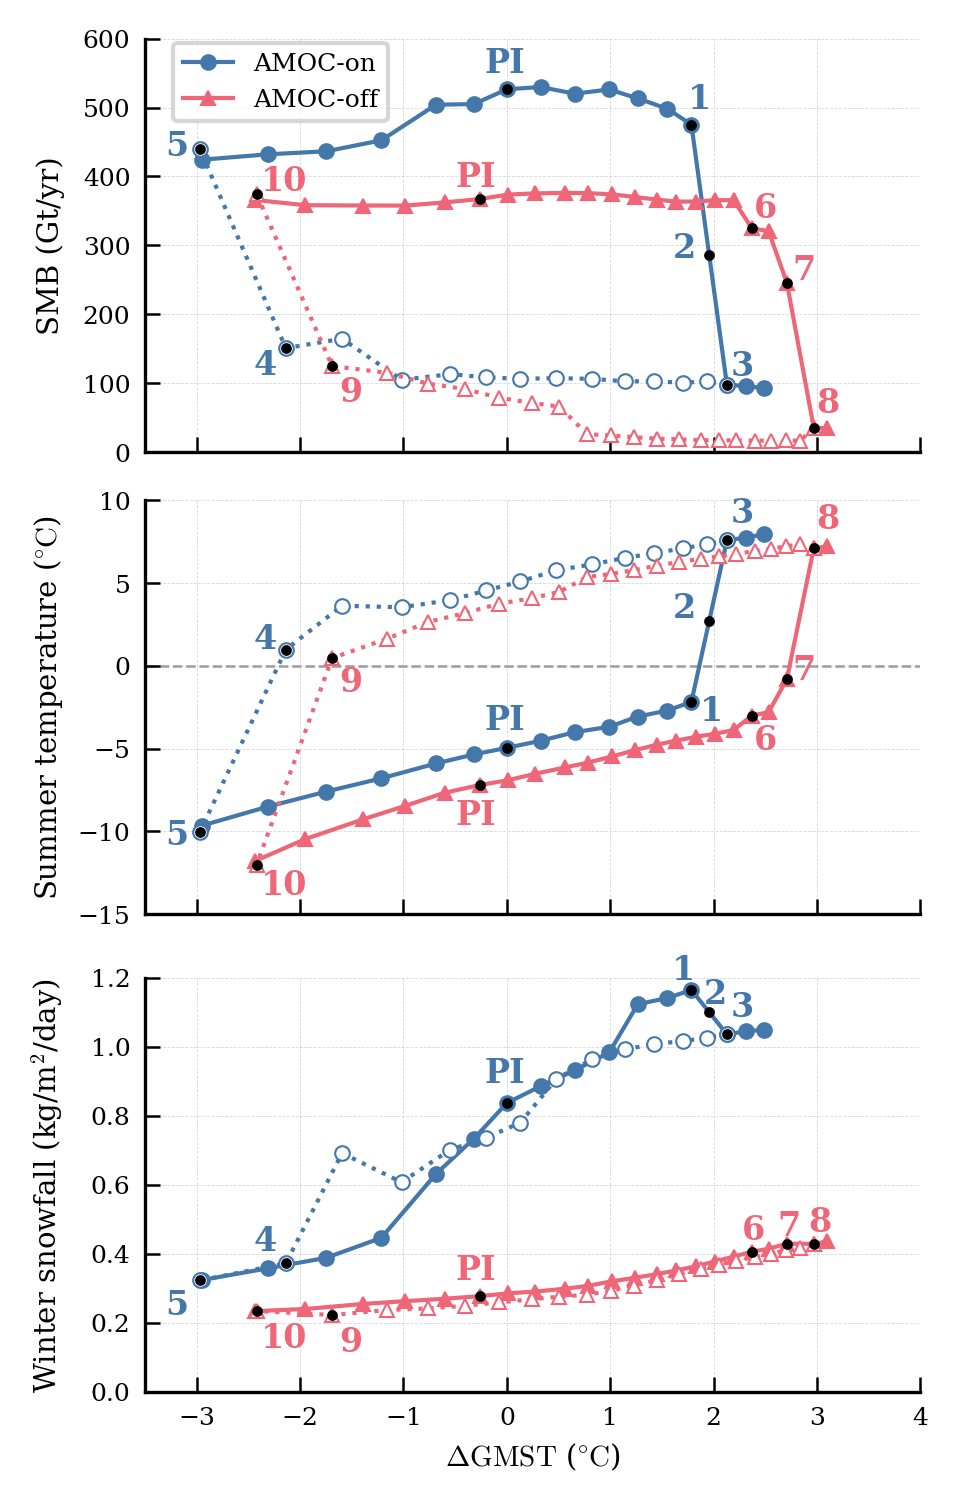

In [18]:
fig, axs = plot.subplots(nrows=3, ncols=1, sharex=True, figsize=(0.9*plot.width_onecol, 1.1*plot.height_twocol))

lw = 1
markersize = 3.5

(ax1, ax2, ax3) = axs


ax1.plot(delta_tg_amoc_on_fw[-len(smb_amoc_on_fw):], smb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", lw=lw)
ax1.plot(delta_tg_amoc_on_bw[:len(smb_amoc_on_bw)], smb_amoc_on_bw, linestyle=':', color=plot.get_color(0), lw=lw)
ax1.plot(delta_tg_amoc_on_bw[:len(smb_amoc_on_bw)], smb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(0), lw=lw)

ax1.plot(delta_tg_amoc_off_fw[-len(smb_amoc_off_fw):], smb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", lw=lw)
ax1.plot(delta_tg_amoc_off_bw[:len(smb_amoc_off_bw)], smb_amoc_off_bw, linestyle=':', color=plot.get_color(1), lw=lw)
ax1.plot(delta_tg_amoc_off_bw[:len(smb_amoc_off_bw)], smb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(1), lw=lw)


ax1.set_ylabel("SMB (Gt/yr)")
ax1.set_ylim(0, 600)
ax1.grid(alpha=0.5)

ax2.plot(delta_tg_amoc_on_fw[-len(t2a_amoc_on_fw):], t2a_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", lw=lw)
ax2.plot(delta_tg_amoc_on_bw[:len(t2a_amoc_on_bw)], t2a_amoc_on_bw, linestyle=':', color=plot.get_color(0), lw=lw)
ax2.plot(delta_tg_amoc_on_bw[:len(t2a_amoc_on_bw)], t2a_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(0), lw=lw)

ax2.plot(delta_tg_amoc_off_fw[-len(t2a_amoc_off_fw):], t2a_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", lw=lw)
ax2.plot(delta_tg_amoc_off_bw[:len(t2a_amoc_off_bw)], t2a_amoc_off_bw, linestyle=':', color=plot.get_color(1), lw=lw)
ax2.plot(delta_tg_amoc_off_bw[:len(t2a_amoc_off_bw)], t2a_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(1), lw=lw)

ax2.hlines(0, -4, 5, colors='grey', linestyles='dashed', linewidth=0.8, alpha=0.8, zorder=0, lw=0.6)

ax2.set_ylabel(r"Summer temperature ($\!^\circ\!\mathrm{C}$)") # \! for tighter spacing
ax2.set_ylim(-15, 10)
ax2.grid(alpha=0.5)

### Plot mSLE difference with preindustrial w.r.t. precipitation above greenland
ax3.plot(delta_tg_amoc_on_fw[-len(prcs_amoc_on_fw):], prcs_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", lw=lw)
ax3.plot(delta_tg_amoc_on_bw[:len(prcs_amoc_on_bw)], prcs_amoc_on_bw, linestyle=':', color=plot.get_color(0), lw=lw)
ax3.plot(delta_tg_amoc_on_bw[:len(prcs_amoc_on_bw)], prcs_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(0), lw=lw)

ax3.plot(delta_tg_amoc_off_fw[-len(prcs_amoc_off_fw):], prcs_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", lw=lw)
ax3.plot(delta_tg_amoc_off_bw[:len(prcs_amoc_off_bw)], prcs_amoc_off_bw, linestyle=':', color=plot.get_color(1), lw=lw)
ax3.plot(delta_tg_amoc_off_bw[:len(prcs_amoc_off_bw)], prcs_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle='none', color=plot.get_color(1), lw=lw)

ax3.set_ylabel("Winter snowfall (kg/m$^2$/day)")
ax3.set_ylim(0, 1.2)
ax3.grid(alpha=0.5)

ax3.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") 
ax3.set_xlim(-3.5, 4)

datasets_fw_on = [smb_amoc_on_fw, t2a_amoc_on_fw, prcs_amoc_on_fw]
datasets_bw_on = [smb_amoc_on_bw, t2a_amoc_on_bw, prcs_amoc_on_bw]
datasets_fw_off = [smb_amoc_off_fw, t2a_amoc_off_fw, prcs_amoc_off_fw]
datasets_bw_off = [smb_amoc_off_bw, t2a_amoc_off_bw, prcs_amoc_off_bw]

for i, ax in enumerate([ax1, ax2, ax3]):
    ds_fw_on = datasets_fw_on[i]
    ds_bw_on = datasets_bw_on[i]
    ds_fw_off = datasets_fw_off[i]
    ds_bw_off = datasets_bw_off[i]

    # Add small black dot on top of the existing scatter to indicate where numbers belong to
    ax.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], ds_fw_on[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_on_fw[6+insert_offset_amoc_on], ds_fw_on[6+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
    # ds_GIS_ts = xr.open_dataset(os.path.join(DIR_AMOC_ON_FW, "co2_400_420_run-1", "ice_GRL-16KM_ts.nc"))
    # ds_GIS_ts["V_sle"].values[-1]
    # np.float32(3.6015475)
    ax.scatter(np.mean(delta_tg_amoc_on_fw[6+insert_offset_amoc_on:8+insert_offset_amoc_on]), np.mean(ds_fw_on[6+insert_offset_amoc_on:8+insert_offset_amoc_on]), color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_on_fw[7+insert_offset_amoc_on], ds_fw_on[7+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_on_bw[-2], ds_bw_on[-2], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_on_bw[-1], ds_bw_on[-1], color='black', s=s_text, zorder=10, clip_on=False)

    ax.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], ds_fw_off[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_off_fw[12+insert_offset_amoc_off], ds_fw_off[12+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_off_fw[14+insert_offset_amoc_off], ds_fw_off[14+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_off_fw[15+insert_offset_amoc_off], ds_fw_off[15+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_off_bw[-2], ds_bw_off[-2], color='black', s=s_text, zorder=10, clip_on=False)
    ax.scatter(delta_tg_amoc_off_bw[-1], ds_bw_off[-1], color='black', s=s_text, zorder=10, clip_on=False)


# Add letters from the ice thickness subplots to indicate which CO2 level they correspond to
ax1.text(0.438, 0.90, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.7, 0.815, "1", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.68, 0.455, "2", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.755, 0.168, "3", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.14, 0.17, "4", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.0255, 0.7, "5", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')

ax1.text(0.4, 0.625, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.785, 0.55, "6", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.835, 0.4, "7", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.865, 0.08, "8", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.251, 0.105, "9", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax1.text(0.15, 0.616, "10", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')


ax2.text(0.438, 0.43, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.716, 0.45, "1", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.68, 0.7, "2", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.755, 0.93, "3", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.14, 0.625, "4", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.0255, 0.15, "5", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')

ax2.text(0.4, 0.2, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.785, 0.38, "6", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.835, 0.55, "7", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.865, 0.914, "8", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.251, 0.52, "9", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax2.text(0.15, 0.03, "10", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')


ax3.text(0.438, 0.73, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.68, 0.98, "1", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.72, 0.92, "2", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.755, 0.89, "3", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.14, 0.325, "4", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.0255, 0.17, "5", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')

ax3.text(0.4, 0.255, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax3.text(0.77, 0.35, "6", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax3.text(0.815, 0.36, "7", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax3.text(0.855, 0.37, "8", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax3.text(0.251, 0.08, "9", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')
ax3.text(0.15, 0.09, "10", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')


ax1.legend(loc="upper left", bbox_to_anchor=(0.02, 1.02))

fig.align_ylabels(axs)

plt.savefig(os.path.join(DIR_FIG, "SMB_temp_snowfall_vs_GMST.pdf"), format="pdf")


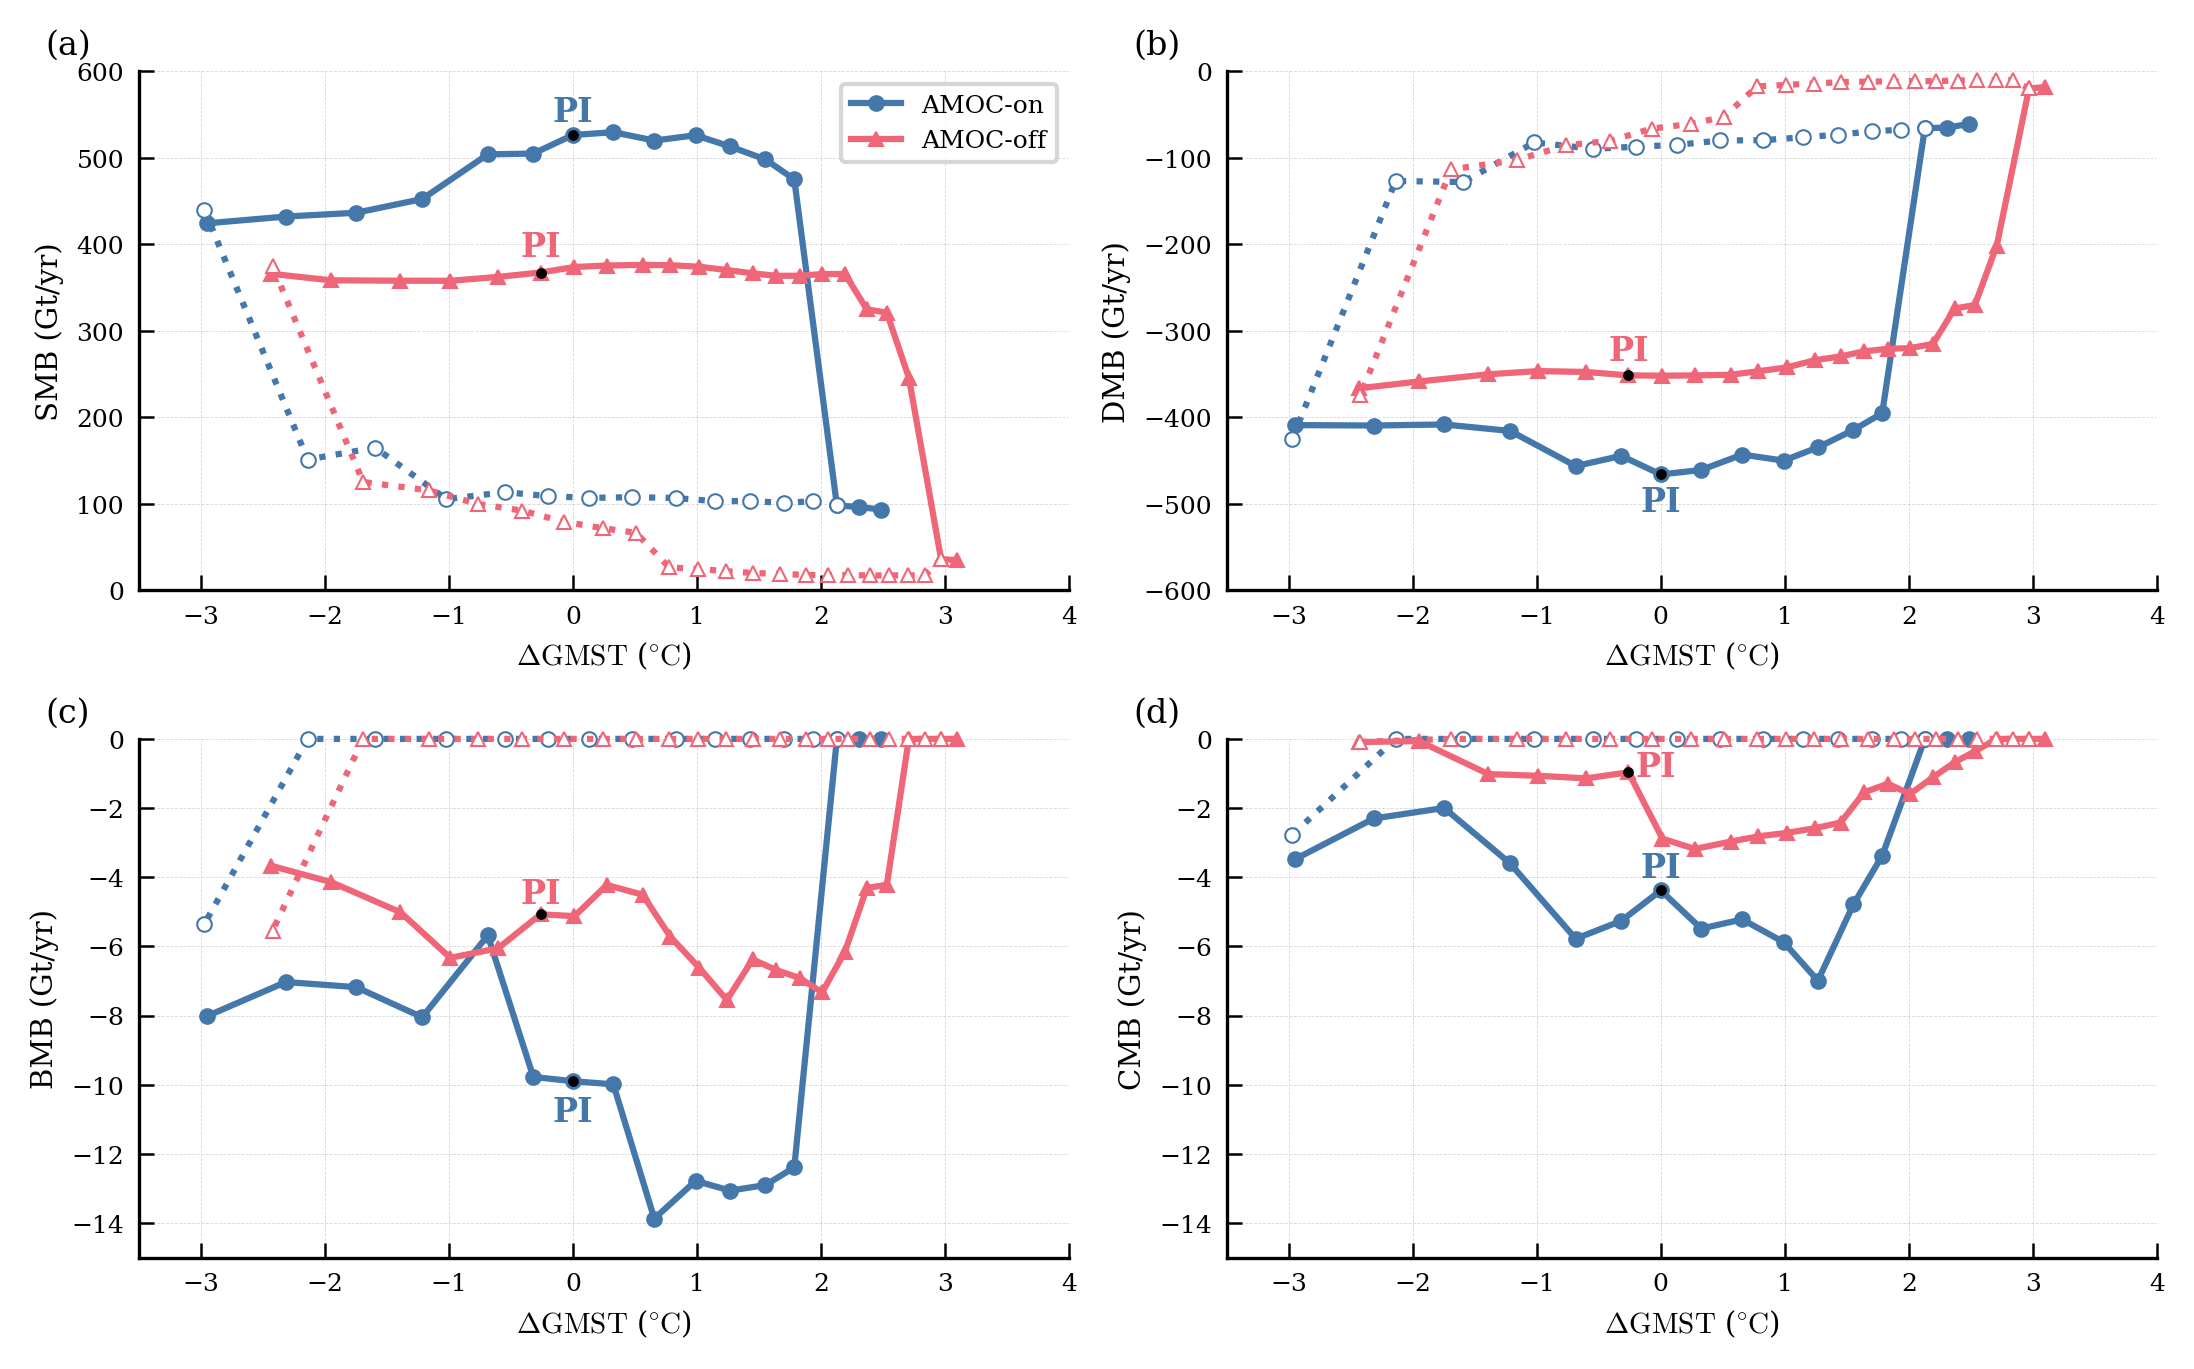

In [19]:
fig, axs = plot.subplots(nrows=2, ncols=2, sharex=False, figsize=(plot.width_twocol, plot.height_twocol), constrained_layout=True)

((ax1, ax2), (ax3, ax4)) = axs

ax1.plot(delta_tg_amoc_on_fw, smb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax1.plot(delta_tg_amoc_on_bw, smb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax1.plot(delta_tg_amoc_off_fw, smb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax1.plot(delta_tg_amoc_off_bw, smb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax1.set_ylabel("SMB (Gt/yr)")
ax1.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") 
ax1.set_xlim(-3.5, 4)
ax1.set_ylim(0, 600)
ax1.grid(alpha=0.5)


ax2.plot(delta_tg_amoc_on_fw, dmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax2.plot(delta_tg_amoc_on_bw, dmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax2.plot(delta_tg_amoc_off_fw, dmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax2.plot(delta_tg_amoc_off_bw, dmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax2.set_ylabel("DMB (Gt/yr)")
ax2.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") 
ax2.set_xlim(-3.5, 4)
ax2.set_ylim(-600, 0)
ax2.grid(alpha=0.5)


ax3.plot(delta_tg_amoc_on_fw, bmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax3.plot(delta_tg_amoc_on_bw, bmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax3.plot(delta_tg_amoc_off_fw, bmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax3.plot(delta_tg_amoc_off_bw, bmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax3.set_ylabel("BMB (Gt/yr)")
ax3.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") 
ax3.set_xlim(-3.5, 4)
ax3.set_ylim(-15, 0)
ax3.grid(alpha=0.5)


ax4.plot(delta_tg_amoc_on_fw, cmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax4.plot(delta_tg_amoc_on_bw, cmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax4.plot(delta_tg_amoc_off_fw, cmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax4.plot(delta_tg_amoc_off_bw, cmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax4.set_ylabel("CMB (Gt/yr)")
ax4.set_xlabel(r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)") 
ax4.set_xlim(-3.5, 4)
ax4.set_ylim(-15, 0)
ax4.grid(alpha=0.5)

ax1.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], smb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], smb_amoc_off_fw[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], dmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], dmb_amoc_off_fw[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax3.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], bmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax3.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], bmb_amoc_off_fw[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)
ax4.scatter(delta_tg_amoc_on_fw[0+insert_offset_amoc_on], cmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax4.scatter(delta_tg_amoc_off_fw[0+insert_offset_amoc_off], cmb_amoc_off_fw[0+insert_offset_amoc_off], color='black', s=s_text, zorder=10, clip_on=False)

ax1.text(0.445, 0.89, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.41, 0.63, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax2.text(0.445, 0.138, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.41, 0.43, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax3.text(0.445, 0.25, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.41, 0.67, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax4.text(0.445, 0.72, "PI", transform=ax4.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax4.text(0.44, 0.915, "PI", transform=ax4.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax1.legend(loc="upper right")

ax1.text(-0.1, 1.02, "(a)", transform=ax1.transAxes,  va='bottom', ha='left')
ax2.text(-0.1, 1.02, "(b)", transform=ax2.transAxes,  va='bottom', ha='left')
ax3.text(-0.1, 1.02, "(c)", transform=ax3.transAxes,  va='bottom', ha='left')
ax4.text(-0.1, 1.02, "(d)", transform=ax4.transAxes,  va='bottom', ha='left')

plt.savefig(os.path.join(DIR_FIG, "Mass_balances_vs_gmst.pdf"), format='pdf')

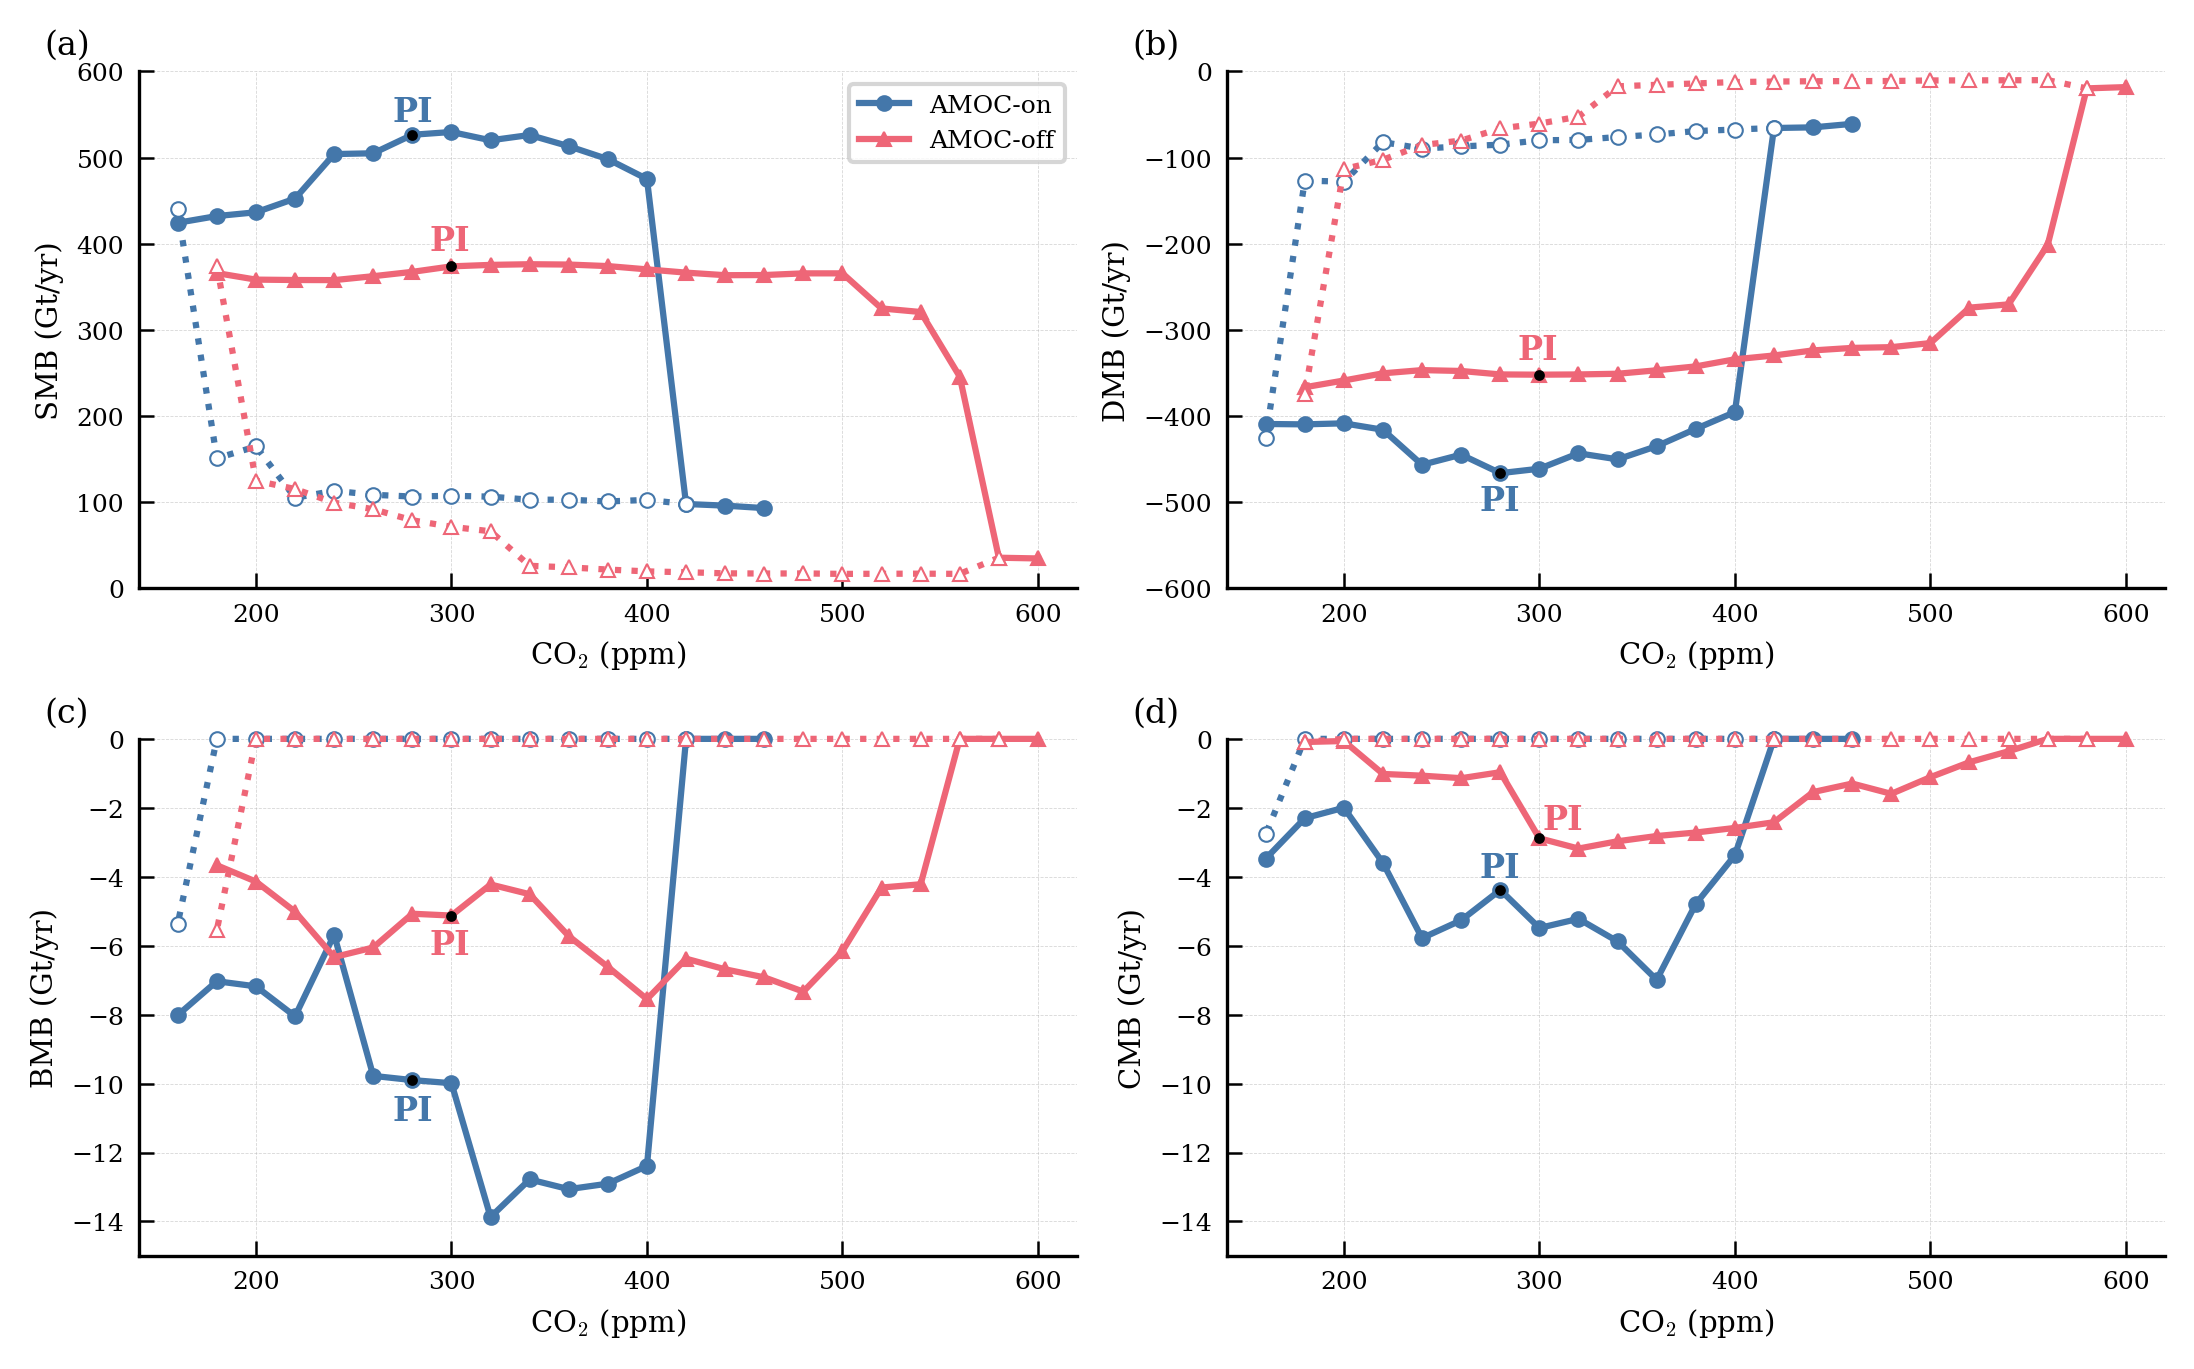

In [20]:
fig, axs = plot.subplots(nrows=2, ncols=2, sharex=False, figsize=(plot.width_twocol, plot.height_twocol), constrained_layout=True)

((ax1, ax2), (ax3, ax4)) = axs

ax1.plot(CO2_amoc_on_fw_output, smb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax1.plot(CO2_amoc_on_bw_output, smb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax1.plot(CO2_amoc_off_fw_output, smb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax1.plot(CO2_amoc_off_bw_output, smb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax1.set_ylabel("SMB (Gt/yr)")
ax1.set_xlabel("CO$_2$ (ppm)")
ax1.set_xlim(140, 620)
ax1.set_ylim(0, 600)
ax1.grid(alpha=0.5)


ax2.plot(CO2_amoc_on_fw_output, dmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax2.plot(CO2_amoc_on_bw_output, dmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax2.plot(CO2_amoc_off_fw_output, dmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax2.plot(CO2_amoc_off_bw_output, dmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax2.set_ylabel("DMB (Gt/yr)")
ax2.set_xlabel("CO$_2$ (ppm)")
ax2.set_xlim(140, 620)
ax2.set_ylim(-600, 0)
ax2.grid(alpha=0.5)


ax3.plot(CO2_amoc_on_fw_output, bmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax3.plot(CO2_amoc_on_bw_output, bmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax3.plot(CO2_amoc_off_fw_output, bmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax3.plot(CO2_amoc_off_bw_output, bmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax3.set_ylabel("BMB (Gt/yr)")
ax3.set_xlabel("CO$_2$ (ppm)")
ax3.set_xlim(140, 620)
ax3.set_ylim(-15, 0)
ax3.grid(alpha=0.5)


ax4.plot(CO2_amoc_on_fw_output, cmb_amoc_on_fw, marker='o', markersize=markersize, linestyle='-', color=plot.get_color(0), label="AMOC-on", clip_on=False)
ax4.plot(CO2_amoc_on_bw_output, cmb_amoc_on_bw, marker='o', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(0), clip_on=False)
ax4.plot(CO2_amoc_off_fw_output, cmb_amoc_off_fw, marker='^', markersize=markersize, linestyle='-', color=plot.get_color(1), label="AMOC-off", clip_on=False)
ax4.plot(CO2_amoc_off_bw_output, cmb_amoc_off_bw, marker='^', markersize=markersize, markerfacecolor='white', linestyle=':', color=plot.get_color(1), clip_on=False)

ax4.set_ylabel("CMB (Gt/yr)")
ax4.set_xlabel("CO$_2$ (ppm)")
ax4.set_xlim(140, 620)
ax4.set_ylim(-15, 0)
ax4.grid(alpha=0.5)

ax1.scatter(CO2_amoc_on_fw_output[0+insert_offset_amoc_on], smb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax1.scatter(CO2_amoc_off_fw_output[0+insert_offset_amoc_on], smb_amoc_off_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(CO2_amoc_on_fw_output[0+insert_offset_amoc_on], dmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax2.scatter(CO2_amoc_off_fw_output[0+insert_offset_amoc_on], dmb_amoc_off_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax3.scatter(CO2_amoc_on_fw_output[0+insert_offset_amoc_on], bmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax3.scatter(CO2_amoc_off_fw_output[0+insert_offset_amoc_on], bmb_amoc_off_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax4.scatter(CO2_amoc_on_fw_output[0+insert_offset_amoc_on], cmb_amoc_on_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)
ax4.scatter(CO2_amoc_off_fw_output[0+insert_offset_amoc_on], cmb_amoc_off_fw[0+insert_offset_amoc_on], color='black', s=s_text, zorder=10, clip_on=False)

ax1.text(0.27, 0.89, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax1.text(0.31, 0.64, "PI", transform=ax1.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax2.text(0.27, 0.138, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax2.text(0.31, 0.43, "PI", transform=ax2.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax3.text(0.27, 0.25, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax3.text(0.31, 0.57, "PI", transform=ax3.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax4.text(0.27, 0.72, "PI", transform=ax4.transAxes, fontweight='bold', color=plot.get_color(0), va='bottom', ha='left')
ax4.text(0.337, 0.812, "PI", transform=ax4.transAxes, fontweight='bold', color=plot.get_color(1), va='bottom', ha='left')

ax1.legend(loc="upper right")

ax1.text(-0.1, 1.02, "(a)", transform=ax1.transAxes,  va='bottom', ha='left')
ax2.text(-0.1, 1.02, "(b)", transform=ax2.transAxes,  va='bottom', ha='left')
ax3.text(-0.1, 1.02, "(c)", transform=ax3.transAxes,  va='bottom', ha='left')
ax4.text(-0.1, 1.02, "(d)", transform=ax4.transAxes,  va='bottom', ha='left')


plt.savefig(os.path.join(DIR_FIG, "Mass_balances_vs_co2.pdf"), format='pdf')

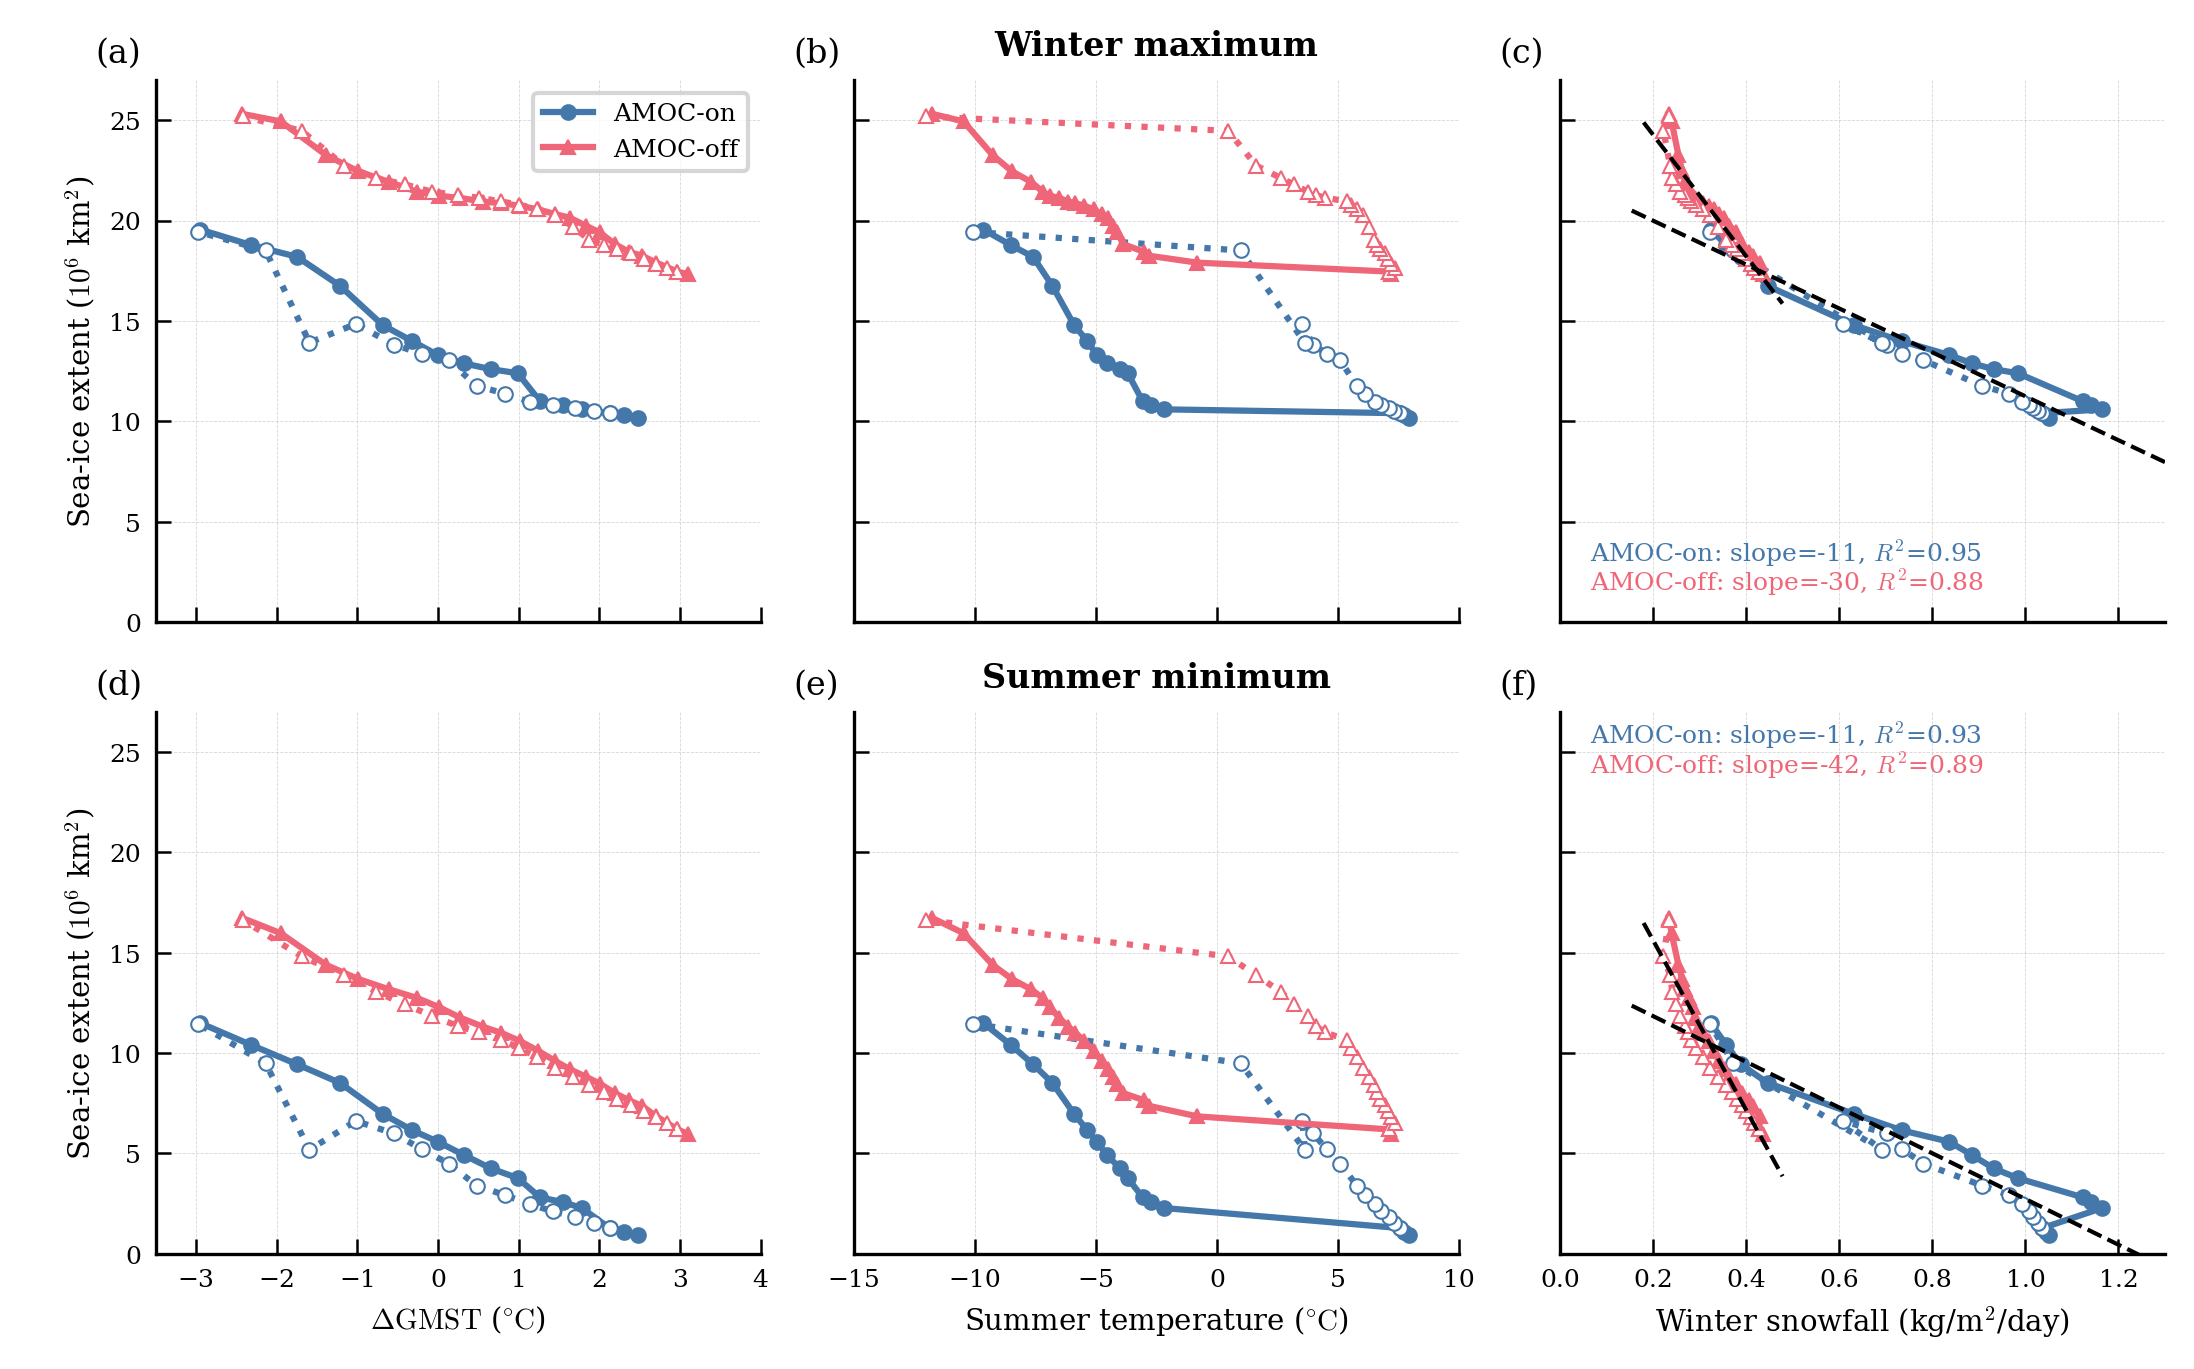

In [29]:
import pandas as pd
from scipy.stats import linregress, t

predictors = [
    ("GMST", delta_tg_amoc_on_fw, delta_tg_amoc_on_bw,
    delta_tg_amoc_off_fw, delta_tg_amoc_off_bw,
    r"$\Delta\text{GMST}$ ($\!^\circ\!\mathrm{C}$)", (-3.5, 4)),
    ("t2a", t2a_amoc_on_fw, t2a_amoc_on_bw,
    t2a_amoc_off_fw, t2a_amoc_off_bw,
    r"Summer temperature ($\!^\circ\!\mathrm{C}$)", (-15, 10)),
    ("prcs", prcs_amoc_on_fw, prcs_amoc_on_bw,
    prcs_amoc_off_fw, prcs_amoc_off_bw,
    "Winter snowfall (kg/m$^2$/day)", (0, 1.3)),
]
responses = [
    ("SIC_max", sic_max_amoc_on_fw, sic_max_amoc_on_bw,
     sic_max_amoc_off_fw, sic_max_amoc_off_bw),
    ("SIC_min", sic_min_amoc_on_fw, sic_min_amoc_on_bw,
     sic_min_amoc_off_fw, sic_min_amoc_off_bw),
]

fig, axs = plot.subplots(
    nrows=2, ncols=3,
    sharey="row",
    sharex="col",
    figsize=(plot.width_twocol, plot.height_twocol),
    constrained_layout=True,
)

colors = [plot.get_color(0), plot.get_color(1)]
markers = ["o", "^"]


def valid_pair(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    return x[valid], y[valid]


def pool_branches(x_fw, y_fw, x_bw, y_bw):
    x, y = valid_pair(
        list(x_fw) + list(x_bw),
        list(y_fw) + list(y_bw),
    )
    _, unique_indices = np.unique(
        np.column_stack((x, y)), axis=0, return_index=True
    )
    unique_indices.sort()
    return x[unique_indices], y[unique_indices]


def fit_line(x, y):
    x, y = valid_pair(x, y)
    if len(x) < 3 or np.ptp(x) == 0:
        return None
    result = linregress(x, y)
    return {
        "slope": float(result.slope),
        "slope_se": float(result.stderr),
        "intercept": float(result.intercept),
        "r_squared": float(result.rvalue ** 2),
        "n": len(x),
        "x_min": float(np.min(x)),
        "x_max": float(np.max(x)),
    }


def compare_slopes(fit_on, fit_off):
    variance_on = fit_on["slope_se"] ** 2
    variance_off = fit_off["slope_se"] ** 2
    standard_error = np.sqrt(variance_on + variance_off)
    if standard_error == 0 or not np.isfinite(standard_error):
        return np.nan, np.nan

    statistic = (fit_on["slope"] - fit_off["slope"]) / standard_error
    degrees_freedom = (variance_on + variance_off) ** 2 / (
        variance_on ** 2 / (fit_on["n"] - 2)
        + variance_off ** 2 / (fit_off["n"] - 2)
    )
    p_value = 2 * t.sf(abs(statistic), degrees_freedom)
    return float(statistic), float(p_value)


for row, (response, on_fw_y, on_bw_y, off_fw_y, off_bw_y) in enumerate(responses):
    for col, (predictor, on_fw_x, on_bw_x, off_fw_x, off_bw_x, xlabel, xlim) in enumerate(predictors):
        ax = axs[row, col]

        # Preserve the forward/backward point and line styling in every panel.
        for x, y, color, marker, branch, label in [
            (on_fw_x, on_fw_y, colors[0], markers[0], "fw", "AMOC-on"),
            (on_bw_x, on_bw_y, colors[0], markers[0], "bw", None),
            (off_fw_x, off_fw_y, colors[1], markers[1], "fw", "AMOC-off"),
            (off_bw_x, off_bw_y, colors[1], markers[1], "bw", None),
        ]:
            ax.plot(
                x, y,
                color=color,
                marker=marker,
                markersize=markersize,
                markerfacecolor="white" if branch == "bw" else color,
                linestyle=":" if branch == "bw" else "-",
                label=label,
                clip_on=False,
            )

        if col == 2:
            on_x, on_y = pool_branches(on_fw_x, on_fw_y, on_bw_x, on_bw_y)
            off_x, off_y = pool_branches(off_fw_x, off_fw_y, off_bw_x, off_bw_y)
            fit_on = fit_line(on_x, on_y)
            fit_off = fit_line(off_x, off_y)
            annotation_rows = []

            for scenario, fit, color in [
                ("AMOC-on", fit_on, colors[0]),
                ("AMOC-off", fit_off, colors[1]),
            ]:
                if fit is None:
                    continue

                fit_x = np.array([
                    fit["x_min"] - 0.2 * (fit["x_max"] - fit["x_min"]),
                    fit["x_max"] + 0.2 * (fit["x_max"] - fit["x_min"]),
                ])
                fit_y = fit["intercept"] + fit["slope"] * fit_x
                ax.plot(
                    fit_x, fit_y,
                    color="black",
                    linestyle="--",
                    linewidth=1,
                    label="Linear fit" if row == 0 else None,
                    zorder=4,
                )
                annotation_rows.append((
                    color,
                    f"{scenario}: slope={fit['slope']:.2g}, $R^2$={fit['r_squared']:.2f}",
                ))

            # if fit_on is not None and fit_off is not None:
            #     delta_slope = fit_off["slope"] - fit_on["slope"]
            #     _, p_value = compare_slopes(fit_on, fit_off)
            #     p_label = "p<0.001" if p_value < 0.001 else f"p={p_value:.2g}"
            #     annotation_rows.append((
            #         "black",
            #         f"$\\Delta$slope={delta_slope:.2g}, {p_label}",
            #     ))

            y_start = 0.1 if row == 0 else 0.93
            for line_index, (text_color, line_text) in enumerate(annotation_rows):
                ax.text(
                    0.05, y_start - 0.055 * line_index, line_text,
                    transform=ax.transAxes,
                    va="bottom", ha="left", fontsize=6,
                    color=text_color,
                )

        ax.set_xlim(xlim)
        ax.set_ylim(0, 27)
        if row == 1:
            ax.set_xlabel(xlabel)

        ax.grid(alpha=0.5)

        if col == 0:
            ax.set_ylabel(f"\nSea-ice extent ($10^6$ km$^2$)")
        if row == 0 and col == 0:
            ax.legend(loc="upper right")

axs[0, 1].set_title("Winter maximum", fontweight="bold", fontsize=8)
axs[1, 1].set_title("Summer minimum", fontweight="bold", fontsize=8)

# Add figure labels 
axs[0, 0].text(-0.1, 1.02, "(a)", transform=axs[0, 0].transAxes,  va='bottom', ha='left')
axs[0, 1].text(-0.1, 1.02, "(b)", transform=axs[0, 1].transAxes,  va='bottom', ha='left')
axs[0, 2].text(-0.1, 1.02, "(c)", transform=axs[0, 2].transAxes,  va='bottom', ha='left')
axs[1, 0].text(-0.1, 1.02, "(d)", transform=axs[1, 0].transAxes,  va='bottom', ha='left')
axs[1, 1].text(-0.1, 1.02, "(e)", transform=axs[1, 1].transAxes,  va='bottom', ha='left')
axs[1, 2].text(-0.1, 1.02, "(f)", transform=axs[1, 2].transAxes,  va='bottom', ha='left')

fig.savefig(os.path.join(DIR_FIG, "sic_linear_regression.pdf"), format="pdf")
# display(fig)

In [23]:
import pandas as pd
from scipy.stats import spearmanr

scenario_data = {
    "AMOC-on": {
        "fw": {
            "GMST": delta_tg_amoc_on_fw,
            "t2a": t2a_amoc_on_fw,
            "prcs": prcs_amoc_on_fw,
            "SIC_max": sic_max_amoc_on_fw,
            "SIC_min": sic_min_amoc_on_fw,
        },
        "bw": {
            "GMST": delta_tg_amoc_on_bw,
            "t2a": t2a_amoc_on_bw,
            "prcs": prcs_amoc_on_bw,
            "SIC_max": sic_max_amoc_on_bw,
            "SIC_min": sic_min_amoc_on_bw,
        },
    },
    "AMOC-off": {
        "fw": {
            "GMST": delta_tg_amoc_off_fw,
            "t2a": t2a_amoc_off_fw,
            "prcs": prcs_amoc_off_fw,
            "SIC_max": sic_max_amoc_off_fw,
            "SIC_min": sic_min_amoc_off_fw,
        },
        "bw": {
            "GMST": delta_tg_amoc_off_bw,
            "t2a": t2a_amoc_off_bw,
            "prcs": prcs_amoc_off_bw,
            "SIC_max": sic_max_amoc_off_bw,
            "SIC_min": sic_min_amoc_off_bw,
        },
    },
}

predictors = ["GMST", "t2a", "prcs"]
responses = ["SIC_max", "SIC_min"]
correlation_rows = []

for scenario, branches in scenario_data.items():
    # Concatenate each forward and backward branch.
    combined = {}
    for column in predictors + responses:
        combined[column] = np.concatenate([
            np.asarray(branches[branch][column], dtype=float)
            for branch in ("fw", "bw")
        ])

    for predictor in predictors:
        for response in responses:
            result = spearmanr(
                combined[predictor],
                combined[response],
                nan_policy="omit",
            )
            correlation_rows.append({
                "scenario": scenario,
                "predictor": predictor,
                "response": response,
                "n": int(np.isfinite(combined[predictor] + combined[response]).sum()),
                "spearman_rho": result.statistic,
                "p_value": result.pvalue,
                "significant": result.pvalue < 0.05,
            })

spearman_results = pd.DataFrame(correlation_rows)
spearman_results

,scenario,predictor,response,n,spearman_rho,p_value,significant
0,AMOC-on,GMST,SIC_max,30,-0.991099,4.543431e-26,True
1,AMOC-on,GMST,SIC_min,30,-0.979083,6.614018e-21,True
2,AMOC-on,t2a,SIC_max,30,-0.817534,3.502194e-08,True
3,AMOC-on,t2a,SIC_min,30,-0.848242,3.245071e-09,True
4,AMOC-on,prcs,SIC_max,30,-0.952826,4.956120e-16,True
5,AMOC-on,prcs,SIC_min,30,-0.935024,3.923823e-14,True
6,AMOC-off,GMST,SIC_max,43,-0.998943,1.797421e-56,True
7,AMOC-off,GMST,SIC_min,43,-0.998339,1.889077e-52,True
8,AMOC-off,t2a,SIC_max,43,-0.699917,1.758332e-07,True
9,AMOC-off,t2a,SIC_min,43,-0.727705,3.227076e-08,True
